# Convective cores

## d_cre / d_ccfs

In [7]:
%%writefile ridge_spatial_structured_cv_core_conv_all_CloudPro_bootstrap.py
from unittest import result
from matplotlib.pylab import i0
import xarray as xr
import numpy as np
import os
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import sys
from statsmodels.tsa.stattools import acf
#import dask
#dask.config.set(scheduler="threads")
#Client(n_workers=8, threads_per_worker=1)
# ------------------------------------------------- 
#  Define functions for local ridge regression and cross-validation
# -------------------------------------------------
def ridge_local_structured_bootstrap(y_net,y_lw,y_sw,alpha,dlnSO4,*X_vars,block_length,n_bootstrap):
    X_list = []
    # -------------------------------------------------
    # Build design matrix (rolling + local variables)
    # -------------------------------------------------
    for X in X_vars:
        # -----------------------------------------
        # CASE 1: rolling variables
        # -----------------------------------------
        if X.ndim == 3:
            # (time, lat_win, lon_win)
            t = X.shape[0]
            X_flat = X.reshape(t, -1)
            X_list.append(X_flat)
        # -----------------------------------------
        # CASE 2: local variables
        # -----------------------------------------
        elif X.ndim == 1:
            # (time,)
            X_list.append(X[:, None])
        else:
            raise ValueError(
                f"Unexpected shape: {X.shape}"
            )
    # -------------------------------------------------
    # Concatenate all predictors
    # -------------------------------------------------
    X = np.concatenate(X_list, axis=1)
    t = X.shape[0]
    # -------------------------------------------------
    # Valid mask
    #
    # NET, LW and SW have already been checked to be
    # aligned in time and space, so we use the same
    # valid mask for all three regressions.
    # -------------------------------------------------
    valid = (np.isfinite(y_net) & np.isfinite(y_lw) & np.isfinite(y_sw) & np.all(np.isfinite(X), axis=1))
    # -------------------------------------------------
    # Output sizes
    # -------------------------------------------------
    coef_size = X.shape[1]
    # -------------------------------------------------
    # Minimum number of valid observations
    # -------------------------------------------------
    n_models = dlnSO4.shape[0]
    dlnSO4_flat = dlnSO4.reshape(n_models,-1)
    # Number of SO4 spatial coefficients
    n_so4_features = dlnSO4_flat.shape[1]
    # SO4_MASS_CON is the last predictor
    so4_start = coef_size - n_so4_features
    # -------------------------------------------------
    # Bootstrap results
    # -------------------------------------------------
    coef_net_boot = np.full((n_bootstrap, coef_size),np.nan)
    coef_lw_boot = np.full((n_bootstrap, coef_size),np.nan)
    coef_sw_boot = np.full((n_bootstrap, coef_size),np.nan)
    erf_net_boot = np.full((n_bootstrap, n_models),np.nan)
    erf_lw_boot = np.full((n_bootstrap, n_models),np.nan)
    erf_sw_boot = np.full((n_bootstrap, n_models),np.nan)
    if valid.sum() < 20:
        return (coef_net_boot, coef_lw_boot, coef_sw_boot, erf_net_boot, erf_lw_boot, erf_sw_boot)
    # -------------------------------------------------
    # Select valid observations
    # -------------------------------------------------
    y_net_clean = y_net[valid]
    y_lw_clean = y_lw[valid]
    y_sw_clean = y_sw[valid]
    #
    X_clean = X[valid]
    #
    n_time = len(y_net_clean)  
    # -------------------------------------------------
    # Block bootstrap
    # -------------------------------------------------
    n_blocks = int(np.ceil(n_time / block_length))
    max_start = n_time - block_length
    for b in range(n_bootstrap):
        # ---------------------------------------------
        # Generate blocks of consecutive observations
        # ---------------------------------------------
        #
        # Blocks are sampled with replacement until we
        # obtain n_time observations.
        #
        # The same temporal indices are used for:
        #   X
        #   NET
        #   LW
        #   SW
        #
        # so the temporal relationship between predictors
        # and all three CRE components is preserved.
        # ---------------------------------------------
        block_starts = np.random.randint(0, max_start + 1, size=n_blocks)
        bootstrap_indices = np.concatenate([np.arange(start, start + block_length) for start in block_starts])[:n_time]
        #bootstrap_indices = np.arange(n_time)
        # -------------------------------------------------
        # Apply bootstrap indices
        # -------------------------------------------------
        X_boot = X_clean[bootstrap_indices]
        y_net_boot = y_net_clean[bootstrap_indices]
        y_lw_boot = y_lw_clean[bootstrap_indices]
        y_sw_boot = y_sw_clean[bootstrap_indices]
        # -------------------------------------------------
        # Standardization
        # -------------------------------------------------
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_boot)
        # -------------------------------------------------
        # NET
        # -------------------------------------------------
        model_net = Ridge(alpha=alpha)
        model_net.fit(X_scaled,y_net_boot)
        coef_net_boot[b, :] = model_net.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4_net = coef_net_boot[b,so4_start:]
        # ERF for each aerosol model
        erf_net_boot[b, :] = np.nansum(beta_so4_net[None, :] * dlnSO4_flat,axis=1)
        # -------------------------------------------------
        # LW
        # -------------------------------------------------
        model_lw = Ridge(alpha=alpha)
        model_lw.fit(X_scaled,y_lw_boot)
        coef_lw_boot[b, :] = model_lw.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4_lw = coef_lw_boot[b,so4_start:]
        # ERF for each aerosol model
        erf_lw_boot[b, :] = np.nansum(beta_so4_lw[None, :] * dlnSO4_flat,axis=1)
        # -------------------------------------------------
        # SW
        # -------------------------------------------------
        model_sw = Ridge(alpha=alpha)
        model_sw.fit(X_scaled,y_sw_boot)
        coef_sw_boot[b, :] = model_sw.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4_sw = coef_sw_boot[b,so4_start:]
        # ERF for each aerosol model
        erf_sw_boot[b, :] = np.nansum(beta_so4_sw[None, :] * dlnSO4_flat,axis=1)
    # -------------------------------------------------
    # Return ERF only
    # -------------------------------------------------
    return coef_net_boot, coef_lw_boot, coef_sw_boot, erf_net_boot, erf_lw_boot, erf_sw_boot
# ------------------------------------------------- 
#  Define function to prepare rolling windows for predictors
# -------------------------------------------------

def prepare_rolling(ds, predictors, lat_win, lon_win, local_vars=None):

    rolled = []

    # -----------------------------
    # Periodic longitud padding
    # -----------------------------
    pad = lon_win // 2
    lon = ds.lon

    ds_left  = ds.isel(lon=slice(-pad, None))
    ds_right = ds.isel(lon=slice(0, pad))

    ds_left  = ds_left.assign_coords(lon=lon[-pad:] - 360)
    ds_right = ds_right.assign_coords(lon=lon[:pad] + 360)

    ds_ext = xr.concat([ds_left, ds, ds_right], dim="lon")

    # -----------------------------
    # Loop over variables
    # -----------------------------
    for var in predictors:

        # =====================================
        # CASE 1: LOCAL VARIABLE (NO ROLLING)
        # =====================================
        if var in local_vars:

            da = ds[var]

            # asegurar chunking consistente
            da = da.chunk({"time": -1})

            rolled.append(da)
            continue
        # =====================================
        # CASE 2: SPATIAL VARIABLE (ROLLING)
        # =====================================
        # Relative offsets within the window
        lat_offsets = np.arange(-(lat_win // 2), lat_win // 2 + 1)
        lon_offsets = np.arange(-(lon_win // 2), lon_win // 2 + 1)

        da = ds_ext[var].rolling(
            lat=lat_win,
            lon=lon_win,
            center=True
        ).construct(
            lat="lat_win",
            lon="lon_win"
        )

        # -----------------------------
        # Turn back to original domain
        # -----------------------------
        da = da.sel(lon=lon)

        # -----------------------------
        # Window physical coordinates
        # -----------------------------
        lat_window = ds.lat.values[:, None] + lat_offsets[None, :]
        lon_window = ds.lon.values[:, None] + lon_offsets[None, :]

        da = da.assign_coords(
            lat_win=(("lat", "lat_win"), lat_window),
            lon_win=(("lon", "lon_win"), lon_window),
        )

        # -----------------------------
        # Chunking for dask
        # -----------------------------
        da = da.chunk({"time": -1})

        rolled.append(da)

    return rolled

# -------------------------------------------------
# Define function to run spatially structured ridge
# regression with bootstrap
# -------------------------------------------------
def ridge_spatial_structured_bootstrap(y_net, y_lw, y_sw, alpha, rolled, predictors, dlnSO4, lat_win, lon_win, block_length, n_bootstrap, local_vars):
    if local_vars is None:
        local_vars = []
    # -------------------------------------------------
    spatial_vars = [v for v in predictors if v not in local_vars]
    n_spatial = len(spatial_vars)
    n_local = len(local_vars)
    coef_size = (n_spatial * lat_win * lon_win + n_local)
    n_models = dlnSO4.shape[0]
    # -------------------------------------------------
    # Run bootstrap ridge
    # -------------------------------------------------
    result = xr.apply_ufunc(ridge_local_structured_bootstrap,
        y_net,
        y_lw,
        y_sw,
        alpha,
        dlnSO4,
        *rolled,
        input_core_dims=[
            ["time"],                         # y_net
            ["time"],                         # y_lw
            ["time"],                         # y_sw
            [],                               # alpha
            ["model", "lat_win", "lon_win"],  # dlnSO4
        ] + [
            ["time", "lat_win", "lon_win"]
            if p not in local_vars
            else ["time"]
            for p in predictors
        ],                   
        output_core_dims=[
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
                ["bootstrap", "model"],
                ["bootstrap", "model"],
                ["bootstrap", "model"],
            ],       
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float, float, float, float],
        kwargs={"block_length": block_length, "n_bootstrap": n_bootstrap,},        
        dask_gufunc_kwargs={
            "output_sizes": {
                "bootstrap": n_bootstrap,
                "coef": coef_size,
                "model": n_models,
            }
        }
    )

    # -------------------------------------------------
    # Convert output to DataArrays
    # -------------------------------------------------
    coef_net = result[0]
    coef_lw  = result[1]
    coef_sw  = result[2]
    
    erf_net = result[3]
    erf_lw  = result[4]
    erf_sw  = result[5]

    # -------------------------------------------------
    # Add component dimension
    # -------------------------------------------------
    ERF_CCF = xr.concat([erf_net, erf_lw, erf_sw], dim="component")
    ERF_CCF = ERF_CCF.assign_coords(component=["net", "lw", "sw"])

    # -------------------------------------------------
    # Split spatial and local coefficients
    # -------------------------------------------------
    def unpack_coefficients(coef, coef_dim):
        coef_spatial_flat = coef.isel({coef_dim: slice(0, n_spatial * lat_win * lon_win)})
        if n_local > 0:
            coef_local = coef.isel({coef_dim: slice(n_spatial * lat_win * lon_win, coef_size)})
            if n_local == 1:
                coef_local = coef_local.isel({coef_dim: 0})
        else:
            coef_local = None
        # -------------------------------------------------
        # Reshape spatial coefficients
        # -------------------------------------------------
        coef_spatial = coef_spatial_flat.data.reshape(coef_spatial_flat.shape[:-1] + (n_spatial, lat_win, lon_win))
        coef_spatial = xr.DataArray(coef_spatial,dims=(coef_spatial_flat.dims[:-1] + ("predictor", "lat_win", "lon_win")),
                                    coords={**{k: coef_spatial_flat.coords[k] for k in coef_spatial_flat.dims if k != coef_dim},
                                            "predictor": spatial_vars, "lat_win": rolled[0].coords["lat_win"], "lon_win": rolled[0].coords["lon_win"],}
                                    )
        return coef_spatial, coef_local
    net = unpack_coefficients(coef_net, "coef")
    lw  = unpack_coefficients(coef_lw,  "coef")
    sw  = unpack_coefficients(coef_sw,  "coef")
    #
    # -------------------------------------------------
    # Return
    # -------------------------------------------------
    return net, lw, sw, ERF_CCF
# -------------------------------------------------
# Run spatially structured ridge regression with bootstrap
# -------------------------------------------------

def main():
    # ------------------------------------------------- 
    #  Load datasets and prepare masks
    # -------------------------------------------------
    res="5deg"
    base_path = "/nobackup/proj/disk/bolinc/personal/alur/AC3S/data"
    file_end_name = f"_monthly_anom_deseasonal_detrended_{res}.nc"
    paths = {
        "CRE": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_CRE_cores{file_end_name}",
        "CLOUD_PROPERTIES": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_cloud_properties_cores{file_end_name}",   
        "DU300": f"{base_path}/ERA5/monthly/processed/DU300{file_end_name}",
        "SUT": f"{base_path}/ERA5/monthly/processed/SUT{file_end_name}",
        "UTRH": f"{base_path}/ERA5/monthly/processed/UTRH{file_end_name}",
        "T2m": f"{base_path}/ERA5/monthly/processed/t2m{file_end_name}",
        "W500": f"{base_path}/ERA5/monthly/processed/W500{file_end_name}",
        "RH700": f"{base_path}/ERA5/monthly/processed/RH_700{file_end_name}",    
        "suaod550": f"{base_path}/CAMS/monthly/processed/suaod550{file_end_name}",
        "SO4CMASS": f"{base_path}/MERRA/monthly/processed/SO4CMASS{file_end_name}",
        "SO4_MASS_CON": f"{base_path}/MERRA/monthly/processed/SO4_MASS_CON{file_end_name}"
    }
    datasets = []
    for path in paths.values():
        ds = xr.open_dataset(path)#.sel(lat=slice(-35, 35),lon=slice(270,290))
        if "CERES_FBCT_DEEP_CRE" in path and "cf_deep" in ds:
            ds = ds.drop_vars("cf_deep")
        ds = ds.chunk({"time": -1, "lat": 4, "lon": 4})  
        # Sort by time
        ds = ds.sortby("time")
            # --- Fix pressure level properly ---
        if "pressure_level" in ds.sizes:
            if "W500" in path:
                ds = ds.sel(pressure_level=500, method="nearest")
            elif "RH_700" in path:
                ds = ds.sel(pressure_level=700, method="nearest")
            ds = ds.drop_vars("pressure_level")   
        # Remove duplicates if they exist
        _, index = np.unique(ds["time"], return_index=True)
        ds = ds.isel(time=index)
        ds["time"] = ds.indexes["time"].to_period("M").to_timestamp()   
        datasets.append(ds)
    ds_all = xr.merge(datasets)
    # ---- Masks ----
    # 1. Cloud mask
    cloud_mask = np.isfinite(ds_all.fbct_cld_eff_temp)
    # 2. Tropics
    tropics_mask = np.abs(ds_all.lat) <= 25
    tropics_2d = tropics_mask.broadcast_like(ds_all["cre_net_deep"].isel(time=0))
    # 3. Valid data fraction
    nt = ds_all.sizes["time"]
    valid_fraction = ds_all["cre_net_deep"].notnull().sum("time") / nt
    data_mask = valid_fraction >= 0.1
    # 4. Ocean mask
    lsm = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/ERA5_land_sea_mask_5deg.nc").isel(time=0)["lsm"]
    ocean_mask = xr.where(lsm > 0, 0, 1)
    # 5. Convective mask
    data_w =xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/W_monthly_ERA5_5deg_corect_dim.nc")
    conv_mask = data_w.W500 < 0
    # 5. Combine masks
    final_mask = tropics_2d & data_mask & ocean_mask & conv_mask & cloud_mask
    final_mask = final_mask.drop_vars("pressure_level")
    # Apply mask
    #ds_masked = ds_all.where(final_mask)
    # ---- Prepare predictors ----
    predictors_SO4_MASS_CON = ['DU300', 'SUT', 'UTRH', 't2m', 'W500', 'RH_700', 'SO4_MASS_CON']
    #
    #
    ds_all = ds_all.chunk({"time": -1, "lat": 4, "lon": 4})
    #
    targets = {
        "net": ds_all["cre_net_deep"].where(final_mask),
        "lw": ds_all["cre_lw_deep"].where(final_mask),
        "sw": ds_all["cre_sw_deep"].where(final_mask),
    }
    #
    lat_win = 27#int(sys.argv[1])
    lon_win = 27#int(sys.argv[2])
    rolled = prepare_rolling(ds_all, predictors_SO4_MASS_CON, lat_win, lon_win, local_vars=[])
    rolled_dask = [X.chunk({"time": -1,"lat": 4,"lon": 4,"lat_win": -1,"lon_win": -1,}) for X in rolled]
    # -------------------------------------------------
    # Load previous ridge results
    # -------------------------------------------------
    previous_file = ("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
    ds_previous = xr.open_dataset(previous_file)
    # Alpha selected previously by cross-validation
    alpha_net = ds_previous.alpha.sel(component="net")
    # -------------------------------------------------
    # Load model dlnso4
    # -------------------------------------------------
    model_so4 = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/so4_925_all_models_5deg_27x27.nc")
    models_dlnSO4 = model_so4.dlnSO4
    # -------------------------------------------------
    # Calculate temporal block length
    # -------------------------------------------------
    # Area weighting
    weights_lat = np.cos(np.deg2rad(ds_all.lat))
    decorrelation_times = []
    max_lag = 24
    threshold = 1 / np.e
    for pre in predictors_SO4_MASS_CON:
        ACF=acf(ds_all[pre].weighted(weights_lat).mean(dim=('lat','lon')),nlags=max_lag,fft=True)
        crossing = np.where(ACF[1:] <= threshold)[0]
        decorrelation_times.append(int(crossing[0] + 1))
    block_length = int(max(decorrelation_times))
    #for block_length in (5,7,10,12,15,20) 
    #------------------------------------------------
    # Run ridge regression with SO4_MASS_CON as predictor
    #------------------------------------------------
    n_bootstrap = 1000#1000
    net, lw, sw, ERF_CCF  = (ridge_spatial_structured_bootstrap(
            y_net=targets["net"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_lw=targets["lw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_sw=targets["sw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            alpha=alpha_net.chunk({"lat": 4,"lon": 4,}),
            rolled=rolled_dask,
            predictors=predictors_SO4_MASS_CON,
            dlnSO4=models_dlnSO4,
            lat_win=lat_win,
            lon_win=lon_win,
            block_length=block_length,
            n_bootstrap=n_bootstrap,
            local_vars=None
        )
    )
    # -------------------------------------------------
    # Compute ERF
    # -------------------------------------------------
    net = [x.compute() if x is not None else None for x in net]
    lw  = [x.compute() if x is not None else None for x in lw]
    sw  = [x.compute() if x is not None else None for x in sw]
    ERF_CCF = xr.concat([x.compute() if x is not None else None for x in ERF_CCF],dim="component")
    
    # Convert to datasets
    results = []
    
    for name, beta in zip(["net", "lw", "sw"], [net, lw, sw]):
        coef_spatial, coef_local = beta    
        ds_out = xr.Dataset({"coef_spatial": coef_spatial,})
        ds_out = ds_out.expand_dims({"component": [name]})
        results.append(ds_out)
    ds_ERF_out = xr.Dataset({"ERF_CCF": ERF_CCF})
    ds_all_out = xr.concat(results, dim="component")
    
    # -------------------------------------------------
    # Convert to Dataset
    # -------------------------------------------------
    
    #return ds_all_out
    ds_all_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
    ds_ERF_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/ERF_Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
if __name__ == "__main__":
     main()

Overwriting ridge_spatial_structured_cv_core_conv_all_CloudPro_bootstrap.py


In [8]:
%%writefile run_ridge_core_conv_all_CloudPro_boostrap.sh
#!/bin/bash
#SBATCH --job-name=run_ridge_core_conv_all_CloudPro_boostrap
#SBATCH -A naiss2026-1-3-cpu
#SBATCH --time=08:00:00
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=16
#SBATCH --mem=0
#SBATCH --output=run_ridge_core_conv_all_CloudPro_boostrap.out
#SBATCH --error=run_ridge_core_conv_all_CloudPro_boostrap.err

# ==============================
# Environment
# ==============================
export OMP_NUM_THREADS=8
export MKL_NUM_THREADS=8
export OPENBLAS_NUM_THREADS=8

module load Miniforge
conda activate envfull

# ==============================
# Start info
# ==============================
echo "========================================"
echo "Job ID: $SLURM_JOB_ID"
echo "Node: $(hostname)"
echo "CPUs allocated: $SLURM_CPUS_PER_TASK"
echo "Start time: $(date)"
echo "Window: 27x27"
echo "========================================"

start_time=$(date +%s)

# ==============================
# Run Python
# ==============================
echo "Starting Python execution..."
echo "Running job ${SLURM_ARRAY_TASK_ID} with window 27x27"
python_start=$(date +%s)

python ridge_spatial_structured_cv_core_conv_all_CloudPro_boostrap.py

python_end=$(date +%s)
echo "Python runtime: $((python_end - python_start)) seconds"

# ==============================
# End info
# ==============================
end_time=$(date +%s)

runtime=$((end_time - start_time))
hours=$((runtime / 3600))
minutes=$(((runtime % 3600) / 60))
seconds=$((runtime % 60))

echo "Total runtime: ${hours}h ${minutes}m ${seconds}s"


echo "========================================"
echo "End time: $(date)"
echo "Total runtime: ${hours}:${minutes}:${seconds}"
echo "========================================"



Overwriting run_ridge_core_conv_all_CloudPro_boostrap.sh


## d_P / d_ccfs

In [3]:
%%writefile ridge_spatial_structured_cv_core_conv_all_CloudProp_ccf_bootstrap.py
from unittest import result
from matplotlib.pylab import i0
import xarray as xr
import numpy as np
import os
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import sys
from statsmodels.tsa.stattools import acf
#import dask
#dask.config.set(scheduler="threads")
#Client(n_workers=8, threads_per_worker=1)
# ------------------------------------------------- 
#  Define functions for local ridge regression and cross-validation
# -------------------------------------------------
def ridge_local_structured_bootstrap(y,alpha,dlnSO4,*X_vars,block_length,n_bootstrap):
    X_list = []
    # -------------------------------------------------
    # Build design matrix (rolling + local variables)
    # -------------------------------------------------
    for X in X_vars:
        # -----------------------------------------
        # CASE 1: rolling variables
        # -----------------------------------------
        if X.ndim == 3:
            # (time, lat_win, lon_win)
            t = X.shape[0]
            X_flat = X.reshape(t, -1)
            X_list.append(X_flat)
        # -----------------------------------------
        # CASE 2: local variables
        # -----------------------------------------
        elif X.ndim == 1:
            # (time,)
            X_list.append(X[:, None])
        else:
            raise ValueError(f"Unexpected shape: {X.shape}")
    # -------------------------------------------------
    # Concatenate all predictors
    # -------------------------------------------------
    X = np.concatenate(X_list, axis=1)
    t = X.shape[0]
    # -------------------------------------------------
    # Valid mask
    # Keep only observations with finite response and predictors
    valid = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    # -------------------------------------------------
    # Output sizes
    # -------------------------------------------------
    coef_size = X.shape[1]
    # -------------------------------------------------
    # Identify the SO4 coefficients (SO4 is the last predictor)
    # -------------------------------------------------
    n_models = dlnSO4.shape[0]
    dlnSO4_flat = dlnSO4.reshape(n_models,-1)
    n_so4_features = dlnSO4_flat.shape[1]
    so4_start = coef_size - n_so4_features
    # -------------------------------------------------
    # Bootstrap results
    # -------------------------------------------------
    coef_boot = np.full((n_bootstrap, coef_size),np.nan)
    adj_boot = np.full((n_bootstrap, n_models),np.nan)
    if valid.sum() < 20:
        return adj_boot#(coef_boot, adj_boot)
    # -------------------------------------------------
    # Select valid observations
    # -------------------------------------------------
    y_clean = y[valid]
    X_clean = X[valid]
    n_time = len(y_clean)  
    # -------------------------------------------------
    # Block bootstrap
    # -------------------------------------------------
    n_blocks = int(np.ceil(n_time / block_length))
    max_start = n_time - block_length
    for b in range(n_bootstrap):
        # ---------------------------------------------
        # Generate blocks of consecutive observations
        # ---------------------------------------------
        block_starts = np.random.randint(0, max_start + 1, size=n_blocks)
        bootstrap_indices = np.concatenate([np.arange(start, start + block_length) for start in block_starts])[:n_time]
        #bootstrap_indices = np.arange(n_time)
        # -------------------------------------------------
        # Apply bootstrap indices
        # -------------------------------------------------
        X_boot = X_clean[bootstrap_indices]
        y_boot = y_clean[bootstrap_indices]
        # -------------------------------------------------
        # Standardization
        # -------------------------------------------------
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_boot)
        # -------------------------------------------------
        # NET
        # -------------------------------------------------
        model = Ridge(alpha=alpha)
        model.fit(X_scaled,y_boot)
        coef_boot[b, :] = model.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4 = coef_boot[b,so4_start:]
        # ADJ for each aerosol model
        adj_boot[b, :] = np.nansum(beta_so4[None, :] * dlnSO4_flat,axis=1)
    # -------------------------------------------------
    # Return ADJ only
    # -------------------------------------------------
    return adj_boot #coef_boot, adj_boot
# ------------------------------------------------- 
#  Define function to prepare rolling windows for predictors
# -------------------------------------------------

def prepare_rolling(ds, predictors, lat_win, lon_win, local_vars=None):

    rolled = []

    # -----------------------------
    # Periodic longitud padding
    # -----------------------------
    pad = lon_win // 2
    lon = ds.lon

    ds_left  = ds.isel(lon=slice(-pad, None))
    ds_right = ds.isel(lon=slice(0, pad))

    ds_left  = ds_left.assign_coords(lon=lon[-pad:] - 360)
    ds_right = ds_right.assign_coords(lon=lon[:pad] + 360)

    ds_ext = xr.concat([ds_left, ds, ds_right], dim="lon")

    # -----------------------------
    # Loop over variables
    # -----------------------------
    for var in predictors:

        # =====================================
        # 🔹 CASE 1: LOCAL VARIABLE (NO ROLLING)
        # =====================================
        if var in local_vars:

            da = ds[var]

            # asegurar chunking consistente
            da = da.chunk({"time": -1})

            rolled.append(da)
            continue
        # =====================================
        # 🔹 CASE 2: SPATIAL VARIABLE (ROLLING)
        # =====================================

        # Relative offsets within the window
        lat_offsets = np.arange(-(lat_win // 2), lat_win // 2 + 1)
        lon_offsets = np.arange(-(lon_win // 2), lon_win // 2 + 1)

        da = ds_ext[var].rolling(
            lat=lat_win,
            lon=lon_win,
            center=True
        ).construct(
            lat="lat_win",
            lon="lon_win"
        )

        # -----------------------------
        # Turn back to original domain
        # -----------------------------
        da = da.sel(lon=lon)

        # -----------------------------
        # Window physical coordinates
        # -----------------------------
        lat_window = ds.lat.values[:, None] + lat_offsets[None, :]
        lon_window = ds.lon.values[:, None] + lon_offsets[None, :]

        da = da.assign_coords(
            lat_win=(("lat", "lat_win"), lat_window),
            lon_win=(("lon", "lon_win"), lon_window),
        )

        # -----------------------------
        # Chunking for dask
        # -----------------------------
        da = da.chunk({"time": -1})

        rolled.append(da)

    return rolled
# -------------------------------------------------
# Define function to run spatially structured ridge
# regression with bootstrap
# -------------------------------------------------
def ridge_spatial_structured_bootstrap(y, alpha, rolled, predictors, dlnSO4, lat_win, lon_win, block_length, n_bootstrap, local_vars):
    if local_vars is None:
        local_vars = []
    # -------------------------------------------------
    # Prepare rolling predictors once
    # -------------------------------------------------
    spatial_vars = [v for v in predictors if v not in local_vars]
    n_spatial = len(spatial_vars)
    n_local = len(local_vars)
    coef_size = (n_spatial * lat_win * lon_win + n_local)
    n_models = dlnSO4.shape[0]
    # -------------------------------------------------
    # Run bootstrap ridge
    # -------------------------------------------------
    result = xr.apply_ufunc(ridge_local_structured_bootstrap,
        y,
        alpha,
        dlnSO4,
        *rolled,
        input_core_dims=[
            ["time"],                         # y
            [],                               # alpha
            ["model", "lat_win", "lon_win"],  # dlnSO4
        ] + [
            ["time", "lat_win", "lon_win"]
            if p not in local_vars
            else ["time"]
            for p in predictors
        ],
        output_core_dims=[
                #["bootstrap", "coef"],
                ["bootstrap", "model"],
            ],       
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float],# float],
        kwargs={"block_length": block_length, "n_bootstrap": n_bootstrap,},       
        dask_gufunc_kwargs={
            "output_sizes": {
                "bootstrap": n_bootstrap,
                #"coef": coef_size,
                "model": n_models,
            }
        }
    )
    # Separate spatial and local coefficients
    #i0 = n_spatial * lat_win * lon_win
    #i1 = i0 + n_local

    #coef_spatial_flat = result[0].isel(coef=slice(0, i0))
    #if n_local > 0:
    #    coef_local = result[0].isel(coef=slice(i0, i1))
    #else:
    #    coef_local = None
    #  --- Reshape coeficientes ---
    #coef_spatial = coef_spatial_flat.data.reshape(
    #    coef_spatial_flat.shape[:-1] + (n_spatial, lat_win, lon_win)
    #)

    #coef_spatial = xr.DataArray(
    #    coef_spatial,
    #    dims=coef_spatial_flat.dims[:-1] + ("predictor", "lat_win", "lon_win"),
    #    coords={
    #        **{k: coef_spatial_flat.coords[k] 
    #           for k in coef_spatial_flat.dims 
    #           if k != "coef"},
    #        "predictor": spatial_vars,
    #        "lat_win": rolled[0].coords["lat_win"],
    #        "lon_win": rolled[0].coords["lon_win"],
    #    },
    #)
    # Aerosol-induced cloud-property change
    #adj_boot = result[0]
    

    return result#coef_spatial, coef_local, adj_boot
# ------------------------------------------------- 
#  Run spatially structured ridge regression with cross-validation
# -------------------------------------------------
#from dask.distributed import Client
def main():
    # ------------------------------------------------- 
    #  Load datasets and prepare masks
    # -------------------------------------------------
    res="5deg"
    base_path = "/nobackup/proj/disk/bolinc/personal/alur/AC3S/data"
    file_end_name = f"_monthly_anom_deseasonal_detrended_{res}.nc"
    paths = {
        "CRE": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_CRE_cores{file_end_name}",
        "CLOUD_PROPERTIES": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_cloud_properties_cores{file_end_name}",    
        "DU300": f"{base_path}/ERA5/monthly/processed/DU300{file_end_name}",
        "SUT": f"{base_path}/ERA5/monthly/processed/SUT{file_end_name}",
        "UTRH": f"{base_path}/ERA5/monthly/processed/UTRH{file_end_name}",
        "T2m": f"{base_path}/ERA5/monthly/processed/t2m{file_end_name}",
        "W500": f"{base_path}/ERA5/monthly/processed/W500{file_end_name}",
        "RH700": f"{base_path}/ERA5/monthly/processed/RH_700{file_end_name}",    
        "suaod550": f"{base_path}/CAMS/monthly/processed/suaod550{file_end_name}",
        "SO4CMASS": f"{base_path}/MERRA/monthly/processed/SO4CMASS{file_end_name}",
        "SO4_MASS_CON": f"{base_path}/MERRA/monthly/processed/SO4_MASS_CON{file_end_name}"
    }
    datasets = []
    for path in paths.values():
        ds = xr.open_dataset(path)#.sel(lat=slice(-35, 35),lon=slice(270,290))
        if "CERES_FBCT_DEEP_CRE" in path and "cf_deep" in ds:
            ds = ds.drop_vars("cf_deep")
        ds = ds.chunk({"time": -1, "lat": 4, "lon": 4})  
        # Sort by time
        ds = ds.sortby("time")
            # --- Fix pressure level properly ---
        if "pressure_level" in ds.sizes:
            if "W500" in path:
                ds = ds.sel(pressure_level=500, method="nearest")
            elif "RH_700" in path:
                ds = ds.sel(pressure_level=700, method="nearest")
            ds = ds.drop_vars("pressure_level")   
        # Remove duplicates if they exist
        _, index = np.unique(ds["time"], return_index=True)
        ds = ds.isel(time=index)
        ds["time"] = ds.indexes["time"].to_period("M").to_timestamp()   
        datasets.append(ds)
    ds_all = xr.merge(datasets)
    # ---- Masks ----
    # 1. Cloud mask
    cloud_mask = np.isfinite(ds_all.fbct_cld_eff_temp)
    # 2. Tropics
    tropics_mask = np.abs(ds_all.lat) <= 25
    tropics_2d = tropics_mask.broadcast_like(ds_all["cre_net_deep"].isel(time=0))
    # 3. Valid data fraction
    nt = ds_all.sizes["time"]
    valid_fraction = ds_all["cre_net_deep"].notnull().sum("time") / nt
    data_mask = valid_fraction >= 0.1
    # 4. Ocean mask
    lsm = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/ERA5_land_sea_mask_5deg.nc").isel(time=0)["lsm"]
    ocean_mask = xr.where(lsm > 0, 0, 1)
    # 5. Convective mask
    data_w =xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/W_monthly_ERA5_5deg_corect_dim.nc")
    conv_mask = data_w.W500 < 0
    # 5. Combine masks
    final_mask = tropics_2d & data_mask & ocean_mask & conv_mask & cloud_mask
    final_mask = final_mask.drop_vars("pressure_level")
    # Apply mask
    #ds_masked = ds_all.where(final_mask)
    # ---- Prepare predictors ----
    predictors_SO4_MASS_CON = ['DU300', 'SUT', 'UTRH', 't2m', 'W500', 'RH_700', 'SO4_MASS_CON']
    #
    #
    ds_all = ds_all.chunk({"time": -1, "lat": 4, "lon": 4})
    #
    targets = {
        "cf_deep": ds_all["cf_deep"],
        "fbct_cld_eff_temp": ds_all["fbct_cld_eff_temp"],
        "fbct_cld_eff_press": ds_all["fbct_cld_eff_press"],
        "fbct_cld_ir_emiss": ds_all["fbct_cld_ir_emiss"],
        "fbct_cld_od": ds_all["fbct_cld_od"],
        "fbct_cld_lwp": ds_all["fbct_cld_lwp"],
        "fbct_cld_iwp": ds_all["fbct_cld_iwp"],
        "fbct_cld_ice_radius": ds_all["fbct_cld_ice_radius"],
        "fbct_cld_liq_radius": ds_all["fbct_cld_liq_radius"],
    }
    lat_win = 27#int(sys.argv[1])
    lon_win = 27#int(sys.argv[2])
    rolled = prepare_rolling(ds_all, predictors_SO4_MASS_CON, lat_win, lon_win, local_vars=[])
    rolled_dask = [X.chunk({"time": -1,"lat": 4,"lon": 4,"lat_win": -1,"lon_win": -1,}) for X in rolled]
    # -------------------------------------------------
    # Load model dlnso4
    # -------------------------------------------------
    model_so4 = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/so4_925_all_models_5deg_27x27.nc")
    models_dlnSO4 = model_so4.dlnSO4
    # -------------------------------------------------
    # Calculate temporal block length
    # -------------------------------------------------
    # Area weighting
    weights_lat = np.cos(np.deg2rad(ds_all.lat))
    decorrelation_times = []
    max_lag = 24
    threshold = 1 / np.e
    for pre in predictors_SO4_MASS_CON:
        ACF=acf(ds_all[pre].weighted(weights_lat).mean(dim=('lat','lon')),nlags=max_lag,fft=True)
        crossing = np.where(ACF[1:] <= threshold)[0]
        decorrelation_times.append(int(crossing[0] + 1))
    block_length = int(max(decorrelation_times))
    #for block_length in (5,7,10,12,15,20) 
    # -------------------------------------------------
    # Run bootstrap independently for each cloud property
    # -------------------------------------------------
    n_bootstrap = 1000#1000
    results = []
    for name, y_var in targets.items():

        print(f"Running ridge bootstrap for {name}")

        y = y_var.where(final_mask).chunk({"time": -1})
        # -------------------------------------------------
        # Each cloud property has its own alpha
        # -------------------------------------------------
        previous_file = (f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
        ds_previous = xr.open_dataset(previous_file)
        # Alpha selected previously by cross-validation
        alpha = ds_previous.alpha.sel(component=name)

        beta = ridge_spatial_structured_bootstrap(
            y=y,
            alpha=alpha.chunk({"lat": 4,"lon": 4,}),
            rolled=rolled_dask,
            predictors=predictors_SO4_MASS_CON,
            dlnSO4=models_dlnSO4,
            lat_win=lat_win,
            lon_win=lon_win,
            block_length=block_length,
            n_bootstrap=n_bootstrap,
            local_vars=None
        )

        #adj_boot = [                          #coef_spatial, coef_local, adj_boot
        #    x.compute() if x is not None else None for x in beta
        #]
        adj_boot = beta.compute()
        ds_out = xr.Dataset({
        #    "coef_spatial": coef_spatial,
            "adj_boot": adj_boot
        })

        # add dimension identifying component
        ds_out = ds_out.expand_dims({"component": [name]})

        results.append(ds_out)

    ds_all_out = xr.concat(results, dim="component")
    ds_all_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
if __name__ == "__main__":
    main()


Overwriting ridge_spatial_structured_cv_core_conv_all_CloudProp_ccf_bootstrap.py


In [ ]:
%%writefile run_ridge_cores_conv_all_cloudProp_ccf_bootstrap.sh
#!/bin/bash
#SBATCH --job-name=run_ridge_cores_conv_all_cloudProp_ccf_bootstrap
#SBATCH -A naiss2026-1-3-cpu
#SBATCH --time=08:00:00
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=16
#SBATCH --mem=0
#SBATCH --output=run_ridge_cores_conv_all_cloudProp_ccf_bootstrap.out
#SBATCH --error=run_ridge_cores_conv_all_cloudProp_ccf_bootstrap.err

# ==============================
# Environment
# ==============================
export OMP_NUM_THREADS=8
export MKL_NUM_THREADS=8
export OPENBLAS_NUM_THREADS=8

module load Miniforge
conda activate envfull

# ==============================
# Start info
# ==============================
echo "========================================"
echo "Job ID: $SLURM_JOB_ID"
echo "Node: $(hostname)"
echo "CPUs allocated: $SLURM_CPUS_PER_TASK"
echo "Start time: $(date)"
echo "Window: 27x27"
echo "========================================"

start_time=$(date +%s)

# ==============================
# Run Python
# ==============================
echo "Starting Python execution..."
echo "Running job ${SLURM_ARRAY_TASK_ID} with window 27x27"
python_start=$(date +%s)

python ridge_spatial_structured_cv_core_conv_all_CloudProp_ccf_bootstrap.py

python_end=$(date +%s)
echo "Python runtime: $((python_end - python_start)) seconds"

# ==============================
# End info
# ==============================
end_time=$(date +%s)

runtime=$((end_time - start_time))
hours=$((runtime / 3600))
minutes=$(((runtime % 3600) / 60))
seconds=$((runtime % 60))

echo "Total runtime: ${hours}h ${minutes}m ${seconds}s"


echo "========================================"
echo "End time: $(date)"
echo "Total runtime: ${hours}:${minutes}:${seconds}"
echo "========================================"



Overwriting run_ridge_cores_conv_all_cloudProp_ccf_bootstrap.sh


## d_cre / d_P

In [11]:
#%%writefile ridge_spatial_structured_cv_core_conv_all_CRE_cloudProp_bootstrap.py
from unittest import result
from matplotlib.pylab import i0
import xarray as xr
import numpy as np
import os
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import sys
from statsmodels.tsa.stattools import acf
#import dask
#dask.config.set(scheduler="threads")
#Client(n_workers=8, threads_per_worker=1)
# ------------------------------------------------- 
#  Define functions for local ridge regression and cross-validation
# -------------------------------------------------
def ridge_local_structured_bootstrap(y_net,y_lw,y_sw,alpha,*X_vars,block_length,n_bootstrap):
    X_list = []
    # -------------------------------------------------
    # Build design matrix (rolling + local variables)
    # -------------------------------------------------
    for X in X_vars:
        # -----------------------------------------
        # CASE 1: rolling variables
        # -----------------------------------------
        if X.ndim == 3:
            # (time, lat_win, lon_win)
            t = X.shape[0]
            X_flat = X.reshape(t, -1)
            X_list.append(X_flat)
        # -----------------------------------------
        # CASE 2: local variables
        # -----------------------------------------
        elif X.ndim == 1:
            # (time,)
            X_list.append(X[:, None])
        else:
            raise ValueError(
                f"Unexpected shape: {X.shape}"
            )
    # -------------------------------------------------
    # Concatenate all predictors
    # -------------------------------------------------
    X = np.concatenate(X_list, axis=1)
    t = X.shape[0]
    # -------------------------------------------------
    # Valid mask
    #
    # NET, LW and SW have already been checked to be
    # aligned in time and space, so we use the same
    # valid mask for all three regressions.
    # -------------------------------------------------
    valid = (np.isfinite(y_net) & np.isfinite(y_lw) & np.isfinite(y_sw) & np.all(np.isfinite(X), axis=1))
    # -------------------------------------------------
    # Output sizes
    # -------------------------------------------------
    coef_size = X.shape[1]
    # 4 statistics:
    # alpha, R2, MSE, Pearson
    #
    # + observed time series
    # + predicted time series
    N_OUT = coef_size + 4 + 2 * t
    # -------------------------------------------------
    # Initialize outputs
    # -------------------------------------------------
    coef_net_boot = np.full((n_bootstrap, coef_size), np.nan)
    coef_lw_boot = np.full((n_bootstrap, coef_size), np.nan)
    coef_sw_boot = np.full((n_bootstrap, coef_size), np.nan)
    #
    # -------------------------------------------------
    # Minimum number of valid observations
    # -------------------------------------------------
    if valid.sum() < 20:
        #
        return (coef_net_boot, coef_lw_boot, coef_sw_boot)
    # -------------------------------------------------
    # Select valid observations
    # -------------------------------------------------
    y_net_clean = y_net[valid]
    y_lw_clean = y_lw[valid]
    y_sw_clean = y_sw[valid]
    #
    X_clean = X[valid]
    n_time = len(y_net_clean)  
    # -------------------------------------------------
    # Block bootstrap
    # -------------------------------------------------
    n_blocks = int(np.ceil(n_time / block_length))
    max_start = n_time - block_length
    for b in range(n_bootstrap):
        # ---------------------------------------------
        # Generate blocks of consecutive observations
        # ---------------------------------------------
        #
        # Blocks are sampled with replacement until we
        # obtain n_time observations.
        #
        # The same temporal indices are used for:
        #   X
        #   NET
        #   LW
        #   SW
        #
        # so the temporal relationship between predictors
        # and all three CRE components is preserved.
        # ---------------------------------------------
        block_starts = np.random.randint(0, max_start + 1, size=n_blocks)
        bootstrap_indices = np.concatenate([np.arange(start, start + block_length) for start in block_starts])[:n_time]
        #bootstrap_indices = np.arange(n_time)
        # -------------------------------------------------
        # Apply bootstrap indices
        # -------------------------------------------------
        X_boot = X_clean[bootstrap_indices]
        y_net_boot = y_net_clean[bootstrap_indices]
        y_lw_boot = y_lw_clean[bootstrap_indices]
        y_sw_boot = y_sw_clean[bootstrap_indices]
        # -------------------------------------------------
        # Standardization
        # -------------------------------------------------
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_boot)
        # -------------------------------------------------
        # NET
        # -------------------------------------------------
        model_net = Ridge(alpha=alpha)
        model_net.fit(X_scaled,y_net_boot)
        coef_net_boot[b, :] = model_net.coef_  / scaler.scale_
        # -------------------------------------------------
        # LW
        # -------------------------------------------------
        model_lw = Ridge(alpha=alpha)
        model_lw.fit(X_scaled,y_lw_boot)
        coef_lw_boot[b, :] = model_lw.coef_  / scaler.scale_
        # -------------------------------------------------
        # SW
        # -------------------------------------------------
        model_sw = Ridge(alpha=alpha)
        model_sw.fit(X_scaled,y_sw_boot)
        coef_sw_boot[b, :] = model_sw.coef_  / scaler.scale_
    # -------------------------------------------------
    # Return ERF only
    # -------------------------------------------------
    return coef_net_boot, coef_lw_boot, coef_sw_boot
# ------------------------------------------------- 
#  Define function to prepare rolling windows for predictors
# -------------------------------------------------

def prepare_rolling(ds, predictors, lat_win, lon_win, local_vars=None):

    rolled = []

    # -----------------------------
    # Periodic longitud padding
    # -----------------------------
    pad = lon_win // 2
    lon = ds.lon

    ds_left  = ds.isel(lon=slice(-pad, None))
    ds_right = ds.isel(lon=slice(0, pad))

    ds_left  = ds_left.assign_coords(lon=lon[-pad:] - 360)
    ds_right = ds_right.assign_coords(lon=lon[:pad] + 360)

    ds_ext = xr.concat([ds_left, ds, ds_right], dim="lon")

    # -----------------------------
    # Loop over variables
    # -----------------------------
    for var in predictors:

        # =====================================
        # 🔹 CASE 1: LOCAL VARIABLE (NO ROLLING)
        # =====================================
        if var in local_vars:

            da = ds[var]

            # asegurar chunking consistente
            da = da.chunk({"time": -1})

            rolled.append(da)
            continue
        # =====================================
        # 🔹 CASE 2: SPATIAL VARIABLE (ROLLING)
        # =====================================

        # Relative offsets within the window
        lat_offsets = np.arange(-(lat_win // 2), lat_win // 2 + 1)
        lon_offsets = np.arange(-(lon_win // 2), lon_win // 2 + 1)

        da = ds_ext[var].rolling(
            lat=lat_win,
            lon=lon_win,
            center=True
        ).construct(
            lat="lat_win",
            lon="lon_win"
        )

        # -----------------------------
        # Turn back to original domain
        # -----------------------------
        da = da.sel(lon=lon)

        # -----------------------------
        # Window physical coordinates
        # -----------------------------
        lat_window = ds.lat.values[:, None] + lat_offsets[None, :]
        lon_window = ds.lon.values[:, None] + lon_offsets[None, :]

        da = da.assign_coords(
            lat_win=(("lat", "lat_win"), lat_window),
            lon_win=(("lon", "lon_win"), lon_window),
        )

        # -----------------------------
        # Chunking for dask
        # -----------------------------
        da = da.chunk({"time": -1})

        rolled.append(da)

    return rolled
# ------------------------------------------------- 
#  Define functions to run spatially structured ridge regression with cross-validation
# -------------------------------------------------
def ridge_spatial_structured_bootstrap(y_net, y_lw, y_sw, alpha, rolled, predictors, lat_win, lon_win, block_length, n_bootstrap, local_vars):
    if local_vars is None:
        local_vars = []
    # -------------------------------------------------
    spatial_vars = [v for v in predictors if v not in local_vars]
    n_spatial = len(spatial_vars)
    n_local = len(local_vars)
    coef_size = (n_spatial * lat_win * lon_win + n_local)
    #
    # -------------------------------------------------
    # Run bootstrap ridge
    # -------------------------------------------------
    result = xr.apply_ufunc(ridge_local_structured_bootstrap,
        y_net,
        y_lw,
        y_sw,
        alpha,
        *rolled,
        input_core_dims=[
            ["time"],                         # y_net
            ["time"],                         # y_lw
            ["time"],                         # y_sw
            [],                               # alpha
        ] + [
            ["time", "lat_win", "lon_win"]
            if p not in local_vars
            else ["time"]
            for p in predictors
        ],                   
        output_core_dims=[
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
            ],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float],
        kwargs={"block_length": block_length, "n_bootstrap": n_bootstrap,},
        dask_gufunc_kwargs={
            "output_sizes": {
                "bootstrap": n_bootstrap,
                "coef": coef_size,
            }
        }
    )

    # -------------------------------------------------
    # Convert output to DataArrays
    # -------------------------------------------------
    coef_net = result[0]
    coef_lw  = result[1]
    coef_sw  = result[2]

    # -------------------------------------------------
    # Split spatial and local coefficients
    # -------------------------------------------------
    def unpack_coefficients(coef, coef_dim):
        coef_spatial_flat = coef.isel({coef_dim: slice(0, n_spatial * lat_win * lon_win)})
        if n_local > 0:
            coef_local = coef.isel({coef_dim: slice(n_spatial * lat_win * lon_win, coef_size)})
            if n_local == 1:
                coef_local = coef_local.isel({coef_dim: 0})
        else:
            coef_local = None
        # -------------------------------------------------
        # Reshape spatial coefficients
        # -------------------------------------------------
        coef_spatial = coef_spatial_flat.data.reshape(coef_spatial_flat.shape[:-1] + (n_spatial, lat_win, lon_win))
        coef_spatial = xr.DataArray(coef_spatial,dims=(coef_spatial_flat.dims[:-1] + ("predictor", "lat_win", "lon_win")),
                                    coords={**{k: coef_spatial_flat.coords[k] for k in coef_spatial_flat.dims if k != coef_dim},
                                            "predictor": spatial_vars, "lat_win": rolled[0].coords["lat_win"], "lon_win": rolled[0].coords["lon_win"],}
                                    )
        return coef_spatial#, coef_local
    # Unpack NET, LW and SW
    net = unpack_coefficients(coef_net, "coef")
    lw  = unpack_coefficients(coef_lw,  "coef")
    sw  = unpack_coefficients(coef_sw,  "coef")

    return net, lw, sw
# ------------------------------------------------- 
#  Run spatially structured ridge regression with cross-validation
# -------------------------------------------------
#from dask.distributed import Client

def main():
    # ------------------------------------------------- 
    #  Load datasets and prepare masks
    # -------------------------------------------------
    res="5deg"
    base_path = "/nobackup/proj/disk/bolinc/personal/alur/AC3S/data"
    file_end_name = f"_monthly_anom_deseasonal_detrended_{res}.nc"
    paths = {
        "CRE": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_CRE_cores{file_end_name}",
        "CLOUD_PROPERTIES": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_cloud_properties_cores{file_end_name}",   
        "DU300": f"{base_path}/ERA5/monthly/processed/DU300{file_end_name}",
        "SUT": f"{base_path}/ERA5/monthly/processed/SUT{file_end_name}",
        "UTRH": f"{base_path}/ERA5/monthly/processed/UTRH{file_end_name}",
        "T2m": f"{base_path}/ERA5/monthly/processed/t2m{file_end_name}",
        "W500": f"{base_path}/ERA5/monthly/processed/W500{file_end_name}",
        "RH700": f"{base_path}/ERA5/monthly/processed/RH_700{file_end_name}",    
        "suaod550": f"{base_path}/CAMS/monthly/processed/suaod550{file_end_name}",
        "SO4CMASS": f"{base_path}/MERRA/monthly/processed/SO4CMASS{file_end_name}",
        "SO4_MASS_CON": f"{base_path}/MERRA/monthly/processed/SO4_MASS_CON{file_end_name}"
    }
    datasets = []
    for path in paths.values():
        ds = xr.open_dataset(path)#.sel(lat=slice(-35, 35),lon=slice(270,290))
        if "CERES_FBCT_DEEP_CRE" in path and "cf_deep" in ds:
            ds = ds.drop_vars("cf_deep")
        ds = ds.chunk({"time": -1, "lat": 4, "lon": 4})  
        # Sort by time
        ds = ds.sortby("time")
            # --- Fix pressure level properly ---
        if "pressure_level" in ds.sizes:
            if "W500" in path:
                ds = ds.sel(pressure_level=500, method="nearest")
            elif "RH_700" in path:
                ds = ds.sel(pressure_level=700, method="nearest")
            ds = ds.drop_vars("pressure_level")   
        # Remove duplicates if they exist
        _, index = np.unique(ds["time"], return_index=True)
        ds = ds.isel(time=index)
        ds["time"] = ds.indexes["time"].to_period("M").to_timestamp()   
        datasets.append(ds)
    ds_all = xr.merge(datasets)
    # ---- Masks ----
    # 1. Cloud mask
    cloud_mask = np.isfinite(ds_all.fbct_cld_eff_temp)
    ds_all = ds_all.where(cloud_mask)
    # 2. Tropics
    tropics_mask = np.abs(ds_all.lat) <= 25
    tropics_2d = tropics_mask.broadcast_like(ds_all["cre_net_deep"].isel(time=0))
    # 3. Valid data fraction
    nt = ds_all.sizes["time"]
    valid_fraction = ds_all["cre_net_deep"].notnull().sum("time") / nt
    data_mask = valid_fraction >= 0.1
    # 4. Ocean mask
    lsm = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/ERA5_land_sea_mask_5deg.nc").isel(time=0)["lsm"]
    ocean_mask = xr.where(lsm > 0, 0, 1)
    # 5. Convective mask
    data_w =xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/W_monthly_ERA5_5deg_corect_dim.nc")
    conv_mask = data_w.W500 < 0
    # 5. Combine masks
    final_mask = tropics_2d & data_mask & ocean_mask & conv_mask
    final_mask = final_mask.drop_vars("pressure_level")
    # Apply mask
    #ds_masked = ds_all.where(final_mask)
    # ---- Prepare predictors ----
    predictors = ['cf_deep', 'fbct_cld_eff_temp', 'fbct_cld_eff_press', 'fbct_cld_ir_emiss', 'fbct_cld_od', 'fbct_cld_lwp', 'fbct_cld_iwp', 'fbct_cld_ice_radius', 'fbct_cld_liq_radius']
    #
    #
    ds_all = ds_all.chunk({"time": -1, "lat": 4, "lon": 4})
    #
    targets = {
        "net": ds_all["cre_net_deep"].where(final_mask),
        "lw": ds_all["cre_lw_deep"].where(final_mask),
        "sw": ds_all["cre_sw_deep"].where(final_mask),
    }
    #
    lat_win = 1#int(sys.argv[1])
    lon_win = 1#int(sys.argv[2])
    #alphas = [0.1, 1]
    alphas = np.logspace(-4, 4, 20)
    rolled = prepare_rolling(ds_all, predictors, lat_win, lon_win, local_vars=[])
    rolled_dask = [X.chunk({"time": -1,"lat": 4,"lon": 4,"lat_win": -1,"lon_win": -1,}) for X in rolled]
    # -------------------------------------------------
    # Load previous ridge results
    # -------------------------------------------------
    previous_file = ("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_1x1_results_5deg_cores_ALL_components_conv_CRE_CloudPro.nc")
    ds_previous = xr.open_dataset(previous_file)
    # Alpha selected previously by cross-validation
    alpha_net = ds_previous.alpha.sel(component="net")
    # -------------------------------------------------
    # Calculate temporal block length
    # -------------------------------------------------
    # Area weighting
    weights_lat = np.cos(np.deg2rad(ds_all.lat))
    decorrelation_times = []
    max_lag = 24
    threshold = 1 / np.e
    for pre in predictors:
        ACF=acf(ds_all[pre].weighted(weights_lat).mean(dim=('lat','lon')),nlags=max_lag,fft=True)
        crossing = np.where(ACF[1:] <= threshold)[0]
        decorrelation_times.append(int(crossing[0] + 1))
    block_length = int(max(decorrelation_times))
    #for block_length in (5,7,10,12,15,20) 
    #------------------------------------------------
    # Run ridge regression 
    #------------------------------------------------
    n_bootstrap = 1000#1000
    net, lw, sw = (ridge_spatial_structured_bootstrap(
            y_net=targets["net"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_lw=targets["lw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_sw=targets["sw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            alpha=alpha_net.chunk({"lat": 4,"lon": 4,}),
            rolled=rolled_dask,
            predictors=predictors,
            lat_win=lat_win,
            lon_win=lon_win,
            block_length=block_length,
            n_bootstrap=n_bootstrap,
            local_vars=None
        )
    )
    # Compute all components
    net = net.compute()
    lw = lw.compute()
    sw = sw.compute()
    
    # Convert to datasets
    results = []

    for name, coef_spatial in zip(["net", "lw", "sw"],[net, lw, sw]):
        ds_out = xr.Dataset({ "coef_spatial": coef_spatial})
        ds_out = ds_out.expand_dims({"component": [name]})
        results.append(ds_out)
    ds_all_out = xr.concat(results, dim="component")
    #return ds_all_out
    ds_all_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_cores_ALL_components_conv_CRE_CloudPro.nc")
if __name__ == "__main__":
    main()

# Convective anvils

## d_cre / d_ccfs

In [2]:
#%%writefile ridge_spatial_structured_cv_anvils_conv_all_CloudPro_boostrap.py
from unittest import result
from matplotlib.pylab import i0
import xarray as xr
import numpy as np
import os
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import sys
from statsmodels.tsa.stattools import acf
#import dask
#dask.config.set(scheduler="threads")
#Client(n_workers=8, threads_per_worker=1)
# ------------------------------------------------- 
#  Define functions for local ridge regression and cross-validation
# -------------------------------------------------
def ridge_local_structured_bootstrap(y_net,y_lw,y_sw,alpha,dlnSO4,*X_vars,block_length,n_bootstrap):
    X_list = []
    # -------------------------------------------------
    # Build design matrix (rolling + local variables)
    # -------------------------------------------------
    for X in X_vars:
        # -----------------------------------------
        # CASE 1: rolling variables
        # -----------------------------------------
        if X.ndim == 3:
            # (time, lat_win, lon_win)
            t = X.shape[0]
            X_flat = X.reshape(t, -1)
            X_list.append(X_flat)
        # -----------------------------------------
        # CASE 2: local variables
        # -----------------------------------------
        elif X.ndim == 1:
            # (time,)
            X_list.append(X[:, None])
        else:
            raise ValueError(
                f"Unexpected shape: {X.shape}"
            )
    # -------------------------------------------------
    # Concatenate all predictors
    # -------------------------------------------------
    X = np.concatenate(X_list, axis=1)
    t = X.shape[0]
    # -------------------------------------------------
    # Valid mask
    #
    # NET, LW and SW have already been checked to be
    # aligned in time and space, so we use the same
    # valid mask for all three regressions.
    # -------------------------------------------------
    valid = (np.isfinite(y_net) & np.isfinite(y_lw) & np.isfinite(y_sw) & np.all(np.isfinite(X), axis=1))
    # -------------------------------------------------
    # Output sizes
    # -------------------------------------------------
    coef_size = X.shape[1]
    # -------------------------------------------------
    # Minimum number of valid observations
    # -------------------------------------------------
    n_models = dlnSO4.shape[0]
    dlnSO4_flat = dlnSO4.reshape(n_models,-1)
    # Number of SO4 spatial coefficients
    n_so4_features = dlnSO4_flat.shape[1]
    # SO4_MASS_CON is the last predictor
    so4_start = coef_size - n_so4_features
    # -------------------------------------------------
    # Bootstrap results
    # -------------------------------------------------
    coef_net_boot = np.full((n_bootstrap, coef_size),np.nan)
    coef_lw_boot = np.full((n_bootstrap, coef_size),np.nan)
    coef_sw_boot = np.full((n_bootstrap, coef_size),np.nan)
    erf_net_boot = np.full((n_bootstrap, n_models),np.nan)
    erf_lw_boot = np.full((n_bootstrap, n_models),np.nan)
    erf_sw_boot = np.full((n_bootstrap, n_models),np.nan)
    if valid.sum() < 20:
        return (coef_net_boot, coef_lw_boot, coef_sw_boot, erf_net_boot, erf_lw_boot, erf_sw_boot)
    # -------------------------------------------------
    # Select valid observations
    # -------------------------------------------------
    y_net_clean = y_net[valid]
    y_lw_clean = y_lw[valid]
    y_sw_clean = y_sw[valid]
    #
    X_clean = X[valid]
    #
    n_time = len(y_net_clean)  

    # -------------------------------------------------
    # Block bootstrap
    # -------------------------------------------------
    n_blocks = int(np.ceil(n_time / block_length))
    max_start = n_time - block_length
    for b in range(n_bootstrap):
        # ---------------------------------------------
        # Generate blocks of consecutive observations
        # ---------------------------------------------
        #
        # Blocks are sampled with replacement until we
        # obtain n_time observations.
        #
        # The same temporal indices are used for:
        #   X
        #   NET
        #   LW
        #   SW
        #
        # so the temporal relationship between predictors
        # and all three CRE components is preserved.
        # ---------------------------------------------
        block_starts = np.random.randint(0, max_start + 1, size=n_blocks)
        bootstrap_indices = np.concatenate([np.arange(start, start + block_length) for start in block_starts])[:n_time]
        #bootstrap_indices = np.arange(n_time)
        # -------------------------------------------------
        # Apply bootstrap indices
        # -------------------------------------------------
        X_boot = X_clean[bootstrap_indices]
        y_net_boot = y_net_clean[bootstrap_indices]
        y_lw_boot = y_lw_clean[bootstrap_indices]
        y_sw_boot = y_sw_clean[bootstrap_indices]
        # -------------------------------------------------
        # Standardization
        # -------------------------------------------------
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_boot)
        # -------------------------------------------------
        # NET
        # -------------------------------------------------
        model_net = Ridge(alpha=alpha)
        model_net.fit(X_scaled,y_net_boot)
        coef_net_boot[b, :] = model_net.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4_net = coef_net_boot[b,so4_start:]
        # ERF for each aerosol model
        #erf_net_boot[b, :] = np.nansum(beta_so4_net[None, :] * dlnSO4_flat,axis=1)
        # Validity mask: at least one SO4 coefficient must be available
        valid_so4_net = np.isfinite(beta_so4_net).any()
        # ERF for each aerosol model
        erf_net_boot[b, :] = np.where(valid_so4_net,np.nansum(beta_so4_net[None, :] * dlnSO4_flat, axis=1), np.nan)
        # -------------------------------------------------
        # LW
        # -------------------------------------------------
        model_lw = Ridge(alpha=alpha)
        model_lw.fit(X_scaled,y_lw_boot)
        coef_lw_boot[b, :] = model_lw.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4_lw = coef_lw_boot[b,so4_start:]
        # ERF for each aerosol model
        #erf_lw_boot[b, :] = np.nansum(beta_so4_lw[None, :] * dlnSO4_flat,axis=1)
        # Validity mask: at least one SO4 coefficient must be available
        valid_so4_lw = np.isfinite(beta_so4_lw).any()
        # ERF for each aerosol model
        erf_lw_boot[b, :] = np.where(valid_so4_lw,np.nansum(beta_so4_lw[None, :] * dlnSO4_flat, axis=1), np.nan)
        # -------------------------------------------------
        # SW
        # -------------------------------------------------
        model_sw = Ridge(alpha=alpha)
        model_sw.fit(X_scaled,y_sw_boot)
        coef_sw_boot[b, :] = model_sw.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4_sw = coef_sw_boot[b,so4_start:]
        # ERF for each aerosol model
        #erf_sw_boot[b, :] = np.nansum(beta_so4_sw[None, :] * dlnSO4_flat,axis=1)
        # Validity mask: at least one SO4 coefficient must be available
        valid_so4_sw = np.isfinite(beta_so4_sw).any()
        # ERF for each aerosol model
        erf_sw_boot[b, :] = np.where(valid_so4_sw,np.nansum(beta_so4_sw[None, :] * dlnSO4_flat, axis=1), np.nan)
    # -------------------------------------------------
    # Return ERF only
    # -------------------------------------------------
    return coef_net_boot, coef_lw_boot, coef_sw_boot, erf_net_boot, erf_lw_boot, erf_sw_boot
# ------------------------------------------------- 
#  Define function to prepare rolling windows for predictors
# -------------------------------------------------

def prepare_rolling(ds, predictors, lat_win, lon_win, local_vars=None):

    rolled = []

    # -----------------------------
    # Periodic longitud padding
    # -----------------------------
    pad = lon_win // 2
    lon = ds.lon

    ds_left  = ds.isel(lon=slice(-pad, None))
    ds_right = ds.isel(lon=slice(0, pad))

    ds_left  = ds_left.assign_coords(lon=lon[-pad:] - 360)
    ds_right = ds_right.assign_coords(lon=lon[:pad] + 360)

    ds_ext = xr.concat([ds_left, ds, ds_right], dim="lon")

    # -----------------------------
    # Loop over variables
    # -----------------------------
    for var in predictors:

        # =====================================
        # CASE 1: LOCAL VARIABLE (NO ROLLING)
        # =====================================
        if var in local_vars:

            da = ds[var]

            # asegurar chunking consistente
            da = da.chunk({"time": -1})

            rolled.append(da)
            continue
        # =====================================
        # CASE 2: SPATIAL VARIABLE (ROLLING)
        # =====================================
        # Relative offsets within the window
        lat_offsets = np.arange(-(lat_win // 2), lat_win // 2 + 1)
        lon_offsets = np.arange(-(lon_win // 2), lon_win // 2 + 1)

        da = ds_ext[var].rolling(
            lat=lat_win,
            lon=lon_win,
            center=True
        ).construct(
            lat="lat_win",
            lon="lon_win"
        )

        # -----------------------------
        # Turn back to original domain
        # -----------------------------
        da = da.sel(lon=lon)

        # -----------------------------
        # Window physical coordinates
        # -----------------------------
        lat_window = ds.lat.values[:, None] + lat_offsets[None, :]
        lon_window = ds.lon.values[:, None] + lon_offsets[None, :]

        da = da.assign_coords(
            lat_win=(("lat", "lat_win"), lat_window),
            lon_win=(("lon", "lon_win"), lon_window),
        )

        # -----------------------------
        # Chunking for dask
        # -----------------------------
        da = da.chunk({"time": -1})

        rolled.append(da)

    return rolled

# -------------------------------------------------
# Define function to run spatially structured ridge
# regression with bootstrap
# -------------------------------------------------
def ridge_spatial_structured_bootstrap(y_net, y_lw, y_sw, alpha, rolled, predictors, dlnSO4, lat_win, lon_win, block_length, n_bootstrap, local_vars):
    if local_vars is None:
        local_vars = []
    # -------------------------------------------------
    # Prepare rolling predictors once
    # -------------------------------------------------
    spatial_vars = [v for v in predictors if v not in local_vars]
    n_spatial = len(spatial_vars)
    n_local = len(local_vars)
    coef_size = (n_spatial * lat_win * lon_win + n_local)
    n_models = dlnSO4.shape[0]
    # -------------------------------------------------
    # Run bootstrap ridge
    # -------------------------------------------------
    result = xr.apply_ufunc(ridge_local_structured_bootstrap,
        y_net,
        y_lw,
        y_sw,
        alpha,
        dlnSO4,
        *rolled,
        input_core_dims=[
            ["time"],                         # y_net
            ["time"],                         # y_lw
            ["time"],                         # y_sw
            [],                               # alpha
            ["model", "lat_win", "lon_win"],  # dlnSO4
        ] + [
            ["time", "lat_win", "lon_win"]
            if p not in local_vars
            else ["time"]
            for p in predictors
        ],                   
        output_core_dims=[
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
                ["bootstrap", "model"],
                ["bootstrap", "model"],
                ["bootstrap", "model"],
            ],       
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float, float, float, float],
        kwargs={"block_length": block_length, "n_bootstrap": n_bootstrap,},        
        dask_gufunc_kwargs={
            "output_sizes": {
                "bootstrap": n_bootstrap,
                "coef": coef_size,
                "model": n_models,
            }
        }
    )

    # -------------------------------------------------
    # Convert output to DataArrays
    # -------------------------------------------------
    coef_net = result[0]
    coef_lw  = result[1]
    coef_sw  = result[2]
    
    erf_net = result[3]
    erf_lw  = result[4]
    erf_sw  = result[5]

    # -------------------------------------------------
    # Add component dimension
    # -------------------------------------------------
    ERF_CCF = xr.concat([erf_net, erf_lw, erf_sw], dim="component")
    ERF_CCF = ERF_CCF.assign_coords(component=["net", "lw", "sw"])

    # -------------------------------------------------
    # Split spatial and local coefficients
    # -------------------------------------------------
    def unpack_coefficients(coef, coef_dim):
        coef_spatial_flat = coef.isel({coef_dim: slice(0, n_spatial * lat_win * lon_win)})
        if n_local > 0:
            coef_local = coef.isel({coef_dim: slice(n_spatial * lat_win * lon_win, coef_size)})
            if n_local == 1:
                coef_local = coef_local.isel({coef_dim: 0})
        else:
            coef_local = None
        # -------------------------------------------------
        # Reshape spatial coefficients
        # -------------------------------------------------
        coef_spatial = coef_spatial_flat.data.reshape(coef_spatial_flat.shape[:-1] + (n_spatial, lat_win, lon_win))
        coef_spatial = xr.DataArray(coef_spatial,dims=(coef_spatial_flat.dims[:-1] + ("predictor", "lat_win", "lon_win")),
                                    coords={**{k: coef_spatial_flat.coords[k] for k in coef_spatial_flat.dims if k != coef_dim},
                                            "predictor": spatial_vars, "lat_win": rolled[0].coords["lat_win"], "lon_win": rolled[0].coords["lon_win"],}
                                    )
        return coef_spatial, coef_local
    net = unpack_coefficients(coef_net, "coef")
    lw  = unpack_coefficients(coef_lw,  "coef")
    sw  = unpack_coefficients(coef_sw,  "coef")
    #
    # -------------------------------------------------
    # Return
    # -------------------------------------------------
    return net, lw, sw, ERF_CCF
# -------------------------------------------------
# Run spatially structured ridge regression with bootstrap
# -------------------------------------------------

def main():
    # ------------------------------------------------- 
    #  Load datasets and prepare masks
    # -------------------------------------------------
    res="5deg"
    base_path = "/nobackup/proj/disk/bolinc/personal/alur/AC3S/data"
    file_end_name = f"_monthly_anom_deseasonal_detrended_{res}.nc"
    paths = {
        "CRE": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_CRE_anvils{file_end_name}",
        "CLOUD_PROPERTIES": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_cloud_properties_anvils{file_end_name}",   
        "DU300": f"{base_path}/ERA5/monthly/processed/DU300{file_end_name}",
        "SUT": f"{base_path}/ERA5/monthly/processed/SUT{file_end_name}",
        "UTRH": f"{base_path}/ERA5/monthly/processed/UTRH{file_end_name}",
        "T2m": f"{base_path}/ERA5/monthly/processed/t2m{file_end_name}",
        "W500": f"{base_path}/ERA5/monthly/processed/W500{file_end_name}",
        "RH700": f"{base_path}/ERA5/monthly/processed/RH_700{file_end_name}",    
        "suaod550": f"{base_path}/CAMS/monthly/processed/suaod550{file_end_name}",
        "SO4CMASS": f"{base_path}/MERRA/monthly/processed/SO4CMASS{file_end_name}",
        "SO4_MASS_CON": f"{base_path}/MERRA/monthly/processed/SO4_MASS_CON{file_end_name}"
    }
    datasets = []
    for path in paths.values():
        ds = xr.open_dataset(path)#.sel(lat=slice(-35, 35),lon=slice(270,290))
        if "CERES_FBCT_DEEP_CRE" in path and "cf_deep" in ds:
            ds = ds.drop_vars("cf_deep")
        ds = ds.chunk({"time": -1, "lat": 4, "lon": 4})  
        # Sort by time
        ds = ds.sortby("time")
            # --- Fix pressure level properly ---
        if "pressure_level" in ds.sizes:
            if "W500" in path:
                ds = ds.sel(pressure_level=500, method="nearest")
            elif "RH_700" in path:
                ds = ds.sel(pressure_level=700, method="nearest")
            ds = ds.drop_vars("pressure_level")   
        # Remove duplicates if they exist
        _, index = np.unique(ds["time"], return_index=True)
        ds = ds.isel(time=index)
        ds["time"] = ds.indexes["time"].to_period("M").to_timestamp()   
        datasets.append(ds)
    ds_all = xr.merge(datasets)
    # ---- Masks ----
    # 1. Cloud mask
    cloud_mask = np.isfinite(ds_all.fbct_cld_eff_temp)
    # 2. Tropics
    tropics_mask = np.abs(ds_all.lat) <= 25
    tropics_2d = tropics_mask.broadcast_like(ds_all["cre_net_deep"].isel(time=0))
    # 3. Valid data fraction
    nt = ds_all.sizes["time"]
    valid_fraction = ds_all["cre_net_deep"].notnull().sum("time") / nt
    data_mask = valid_fraction >= 0.1
    # 4. Ocean mask
    lsm = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/ERA5_land_sea_mask_5deg.nc").isel(time=0)["lsm"]
    ocean_mask = xr.where(lsm > 0, 0, 1)
    # 5. Convective mask
    data_w =xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/W_monthly_ERA5_5deg_corect_dim.nc")
    conv_mask = data_w.W500 < 0
    # 5. Combine masks
    final_mask = tropics_2d & data_mask & ocean_mask & conv_mask & cloud_mask
    final_mask = final_mask.drop_vars("pressure_level")
    # Apply mask
    #ds_masked = ds_all.where(final_mask)
    # ---- Prepare predictors ----
    predictors_SO4_MASS_CON = ['DU300', 'SUT', 'UTRH', 't2m', 'W500', 'RH_700', 'SO4_MASS_CON']
    #
    #
    ds_all = ds_all.chunk({"time": -1, "lat": 4, "lon": 4})
    #
    targets = {
        "net": ds_all["cre_net_deep"].where(final_mask),
        "lw": ds_all["cre_lw_deep"].where(final_mask),
        "sw": ds_all["cre_sw_deep"].where(final_mask),
    }
    #
    lat_win = 27#int(sys.argv[1])
    lon_win = 27#int(sys.argv[2])
    rolled = prepare_rolling(ds_all, predictors_SO4_MASS_CON, lat_win, lon_win, local_vars=[])
    rolled_dask = [X.chunk({"time": -1,"lat": 4,"lon": 4,"lat_win": -1,"lon_win": -1,}) for X in rolled]
    # -------------------------------------------------
    # Load previous ridge results
    # -------------------------------------------------
    previous_file = ("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")
    ds_previous = xr.open_dataset(previous_file)
    # Alpha selected previously by cross-validation
    alpha_net = ds_previous.alpha.sel(component="net")
    # -------------------------------------------------
    # Load model dlnso4
    # -------------------------------------------------
    model_so4 = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/so4_925_all_models_5deg_27x27.nc")
    models_dlnSO4 = model_so4.dlnSO4
    # -------------------------------------------------
    # Calculate temporal block length
    # -------------------------------------------------
    # Area weighting
    weights_lat = np.cos(np.deg2rad(ds_all.lat))
    decorrelation_times = []
    max_lag = 24
    threshold = 1 / np.e
    for pre in predictors_SO4_MASS_CON:
        ACF=acf(ds_all[pre].weighted(weights_lat).mean(dim=('lat','lon')),nlags=max_lag,fft=True)
        crossing = np.where(ACF[1:] <= threshold)[0]
        decorrelation_times.append(int(crossing[0] + 1))
    block_length = int(max(decorrelation_times))
    #block_length = 5
    #for block_length in (5,7,10,12,15,20) 
    #------------------------------------------------
    # Run ridge regression with SO4_MASS_CON as predictor
    #------------------------------------------------
    n_bootstrap = 100#1000
    net, lw, sw, ERF_CCF  = (ridge_spatial_structured_bootstrap(
            y_net=targets["net"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_lw=targets["lw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_sw=targets["sw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            alpha=alpha_net.chunk({"lat": 4,"lon": 4,}),
            rolled=rolled_dask,
            predictors=predictors_SO4_MASS_CON,
            dlnSO4=models_dlnSO4,
            lat_win=lat_win,
            lon_win=lon_win,
            block_length=block_length,
            n_bootstrap=n_bootstrap,
            local_vars=None
        )
    )
    # -------------------------------------------------
    # Compute ERF
    # -------------------------------------------------
    net = [x.compute() if x is not None else None for x in net]
    lw  = [x.compute() if x is not None else None for x in lw]
    sw  = [x.compute() if x is not None else None for x in sw]
    ERF_CCF = xr.concat([x.compute() if x is not None else None for x in ERF_CCF],dim="component")
    
    # Convert to datasets
    results = []
    
    for name, beta in zip(["net", "lw", "sw"], [net, lw, sw]):
        coef_spatial, coef_local = beta    
        ds_out = xr.Dataset({"coef_spatial": coef_spatial,})
        ds_out = ds_out.expand_dims({"component": [name]})
        results.append(ds_out)
    ds_ERF_out = xr.Dataset({"ERF_CCF": ERF_CCF})
    ds_all_out = xr.concat(results, dim="component")
    
    # -------------------------------------------------
    # Convert to Dataset
    # -------------------------------------------------
    
    return ds_all_out,ds_ERF_out
    #ds_all_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")
    #ds_ERF_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/ERF_Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")
if __name__ == "__main__":
    ds_all_out,ds_ERF_out=main()
    #main()

In [14]:
%%writefile run_ridge_anvils_conv_all_CloudPro_boostrap.sh
#!/bin/bash
#SBATCH --job-name=run_ridge_anvils_conv_all_CloudPro_boostrap
#SBATCH -A naiss2026-1-3-cpu
#SBATCH --time=08:00:00
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=16
#SBATCH --mem=0
#SBATCH --output=run_ridge_anvils_conv_all_CloudPro_boostrap.out
#SBATCH --error=run_ridge_anvils_conv_all_CloudPro_boostrap.err

# ==============================
# Environment
# ==============================
export OMP_NUM_THREADS=8
export MKL_NUM_THREADS=8
export OPENBLAS_NUM_THREADS=8

module load Miniforge
conda activate envfull

# ==============================
# Start info
# ==============================
echo "========================================"
echo "Job ID: $SLURM_JOB_ID"
echo "Node: $(hostname)"
echo "CPUs allocated: $SLURM_CPUS_PER_TASK"
echo "Start time: $(date)"
echo "Window: 27x27"
echo "========================================"

start_time=$(date +%s)

# ==============================
# Run Python
# ==============================
echo "Starting Python execution..."
echo "Running job ${SLURM_ARRAY_TASK_ID} with window 27x27"
python_start=$(date +%s)

python ridge_spatial_structured_cv_anvils_conv_all_CloudPro_boostrap.py

python_end=$(date +%s)
echo "Python runtime: $((python_end - python_start)) seconds"

# ==============================
# End info
# ==============================
end_time=$(date +%s)

runtime=$((end_time - start_time))
hours=$((runtime / 3600))
minutes=$(((runtime % 3600) / 60))
seconds=$((runtime % 60))

echo "Total runtime: ${hours}h ${minutes}m ${seconds}s"


echo "========================================"
echo "End time: $(date)"
echo "Total runtime: ${hours}:${minutes}:${seconds}"
echo "========================================"



Overwriting run_ridge_anvils_conv_all_CloudPro_boostrap.sh


## d_P / d_ccfs

In [9]:
%%writefile ridge_spatial_structured_cv_anvils_conv_all_CloudProp_ccf_bootstrap.py
from unittest import result
from matplotlib.pylab import i0
import xarray as xr
import numpy as np
import os
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import sys
from statsmodels.tsa.stattools import acf
#import dask
#dask.config.set(scheduler="threads")
#Client(n_workers=8, threads_per_worker=1)
# ------------------------------------------------- 
#  Define functions for local ridge regression and cross-validation
# -------------------------------------------------
def ridge_local_structured_bootstrap(y,alpha,dlnSO4,*X_vars,block_length,n_bootstrap):
    X_list = []
    # -------------------------------------------------
    # Build design matrix (rolling + local variables)
    # -------------------------------------------------
    for X in X_vars:
        # -----------------------------------------
        # CASE 1: rolling variables
        # -----------------------------------------
        if X.ndim == 3:
            # (time, lat_win, lon_win)
            t = X.shape[0]
            X_flat = X.reshape(t, -1)
            X_list.append(X_flat)
        # -----------------------------------------
        # CASE 2: local variables
        # -----------------------------------------
        elif X.ndim == 1:
            # (time,)
            X_list.append(X[:, None])
        else:
            raise ValueError(f"Unexpected shape: {X.shape}")
    # -------------------------------------------------
    # Concatenate all predictors
    # -------------------------------------------------
    X = np.concatenate(X_list, axis=1)
    t = X.shape[0]
    # -------------------------------------------------
    # Valid mask
    # Keep only observations with finite response and predictors
    valid = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    # -------------------------------------------------
    # Output sizes
    # -------------------------------------------------
    coef_size = X.shape[1]
    # -------------------------------------------------
    # Identify the SO4 coefficients (SO4 is the last predictor)
    # -------------------------------------------------
    n_models = dlnSO4.shape[0]
    dlnSO4_flat = dlnSO4.reshape(n_models,-1)
    n_so4_features = dlnSO4_flat.shape[1]
    so4_start = coef_size - n_so4_features
    # -------------------------------------------------
    # Bootstrap results
    # -------------------------------------------------
    coef_boot = np.full((n_bootstrap, coef_size),np.nan)
    adj_boot = np.full((n_bootstrap, n_models),np.nan)
    if valid.sum() < 20:
        return adj_boot#(coef_boot, adj_boot)
    # -------------------------------------------------
    # Select valid observations
    # -------------------------------------------------
    y_clean = y[valid]
    X_clean = X[valid]
    n_time = len(y_clean)  
    # -------------------------------------------------
    # Block bootstrap
    # -------------------------------------------------
    n_blocks = int(np.ceil(n_time / block_length))
    max_start = n_time - block_length
    for b in range(n_bootstrap):
        # ---------------------------------------------
        # Generate blocks of consecutive observations
        # ---------------------------------------------
        block_starts = np.random.randint(0, max_start + 1, size=n_blocks)
        bootstrap_indices = np.concatenate([np.arange(start, start + block_length) for start in block_starts])[:n_time]
        #bootstrap_indices = np.arange(n_time)
        # -------------------------------------------------
        # Apply bootstrap indices
        # -------------------------------------------------
        X_boot = X_clean[bootstrap_indices]
        y_boot = y_clean[bootstrap_indices]
        # -------------------------------------------------
        # Standardization
        # -------------------------------------------------
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_boot)
        # -------------------------------------------------
        # NET
        # -------------------------------------------------
        model = Ridge(alpha=alpha)
        model.fit(X_scaled,y_boot)
        coef_boot[b, :] = model.coef_  / scaler.scale_
        # Extract SO4 sensitivity
        beta_so4 = coef_boot[b,so4_start:]
        # ADJ for each aerosol model
        adj_boot[b, :] = np.nansum(beta_so4[None, :] * dlnSO4_flat,axis=1)
    # -------------------------------------------------
    # Return ADJ only
    # -------------------------------------------------
    return adj_boot #coef_boot, adj_boot
# ------------------------------------------------- 
#  Define function to prepare rolling windows for predictors
# -------------------------------------------------

def prepare_rolling(ds, predictors, lat_win, lon_win, local_vars=None):

    rolled = []

    # -----------------------------
    # Periodic longitud padding
    # -----------------------------
    pad = lon_win // 2
    lon = ds.lon

    ds_left  = ds.isel(lon=slice(-pad, None))
    ds_right = ds.isel(lon=slice(0, pad))

    ds_left  = ds_left.assign_coords(lon=lon[-pad:] - 360)
    ds_right = ds_right.assign_coords(lon=lon[:pad] + 360)

    ds_ext = xr.concat([ds_left, ds, ds_right], dim="lon")

    # -----------------------------
    # Loop over variables
    # -----------------------------
    for var in predictors:

        # =====================================
        # 🔹 CASE 1: LOCAL VARIABLE (NO ROLLING)
        # =====================================
        if var in local_vars:

            da = ds[var]

            # asegurar chunking consistente
            da = da.chunk({"time": -1})

            rolled.append(da)
            continue
        # =====================================
        # 🔹 CASE 2: SPATIAL VARIABLE (ROLLING)
        # =====================================

        # Relative offsets within the window
        lat_offsets = np.arange(-(lat_win // 2), lat_win // 2 + 1)
        lon_offsets = np.arange(-(lon_win // 2), lon_win // 2 + 1)

        da = ds_ext[var].rolling(
            lat=lat_win,
            lon=lon_win,
            center=True
        ).construct(
            lat="lat_win",
            lon="lon_win"
        )

        # -----------------------------
        # Turn back to original domain
        # -----------------------------
        da = da.sel(lon=lon)

        # -----------------------------
        # Window physical coordinates
        # -----------------------------
        lat_window = ds.lat.values[:, None] + lat_offsets[None, :]
        lon_window = ds.lon.values[:, None] + lon_offsets[None, :]

        da = da.assign_coords(
            lat_win=(("lat", "lat_win"), lat_window),
            lon_win=(("lon", "lon_win"), lon_window),
        )

        # -----------------------------
        # Chunking for dask
        # -----------------------------
        da = da.chunk({"time": -1})

        rolled.append(da)

    return rolled
# -------------------------------------------------
# Define function to run spatially structured ridge
# regression with bootstrap
# -------------------------------------------------
def ridge_spatial_structured_bootstrap(y, alpha, rolled, predictors, dlnSO4, lat_win, lon_win, block_length, n_bootstrap, local_vars):
    if local_vars is None:
        local_vars = []
    # -------------------------------------------------
    # Prepare rolling predictors once
    # -------------------------------------------------
    spatial_vars = [v for v in predictors if v not in local_vars]
    n_spatial = len(spatial_vars)
    n_local = len(local_vars)
    coef_size = (n_spatial * lat_win * lon_win + n_local)
    n_models = dlnSO4.shape[0]
    # -------------------------------------------------
    # Run bootstrap ridge
    # -------------------------------------------------
    result = xr.apply_ufunc(ridge_local_structured_bootstrap,
        y,
        alpha,
        dlnSO4,
        *rolled,
        input_core_dims=[
            ["time"],                         # y
            [],                               # alpha
            ["model", "lat_win", "lon_win"],  # dlnSO4
        ] + [
            ["time", "lat_win", "lon_win"]
            if p not in local_vars
            else ["time"]
            for p in predictors
        ],
        output_core_dims=[
                #["bootstrap", "coef"],
                ["bootstrap", "model"],
            ],       
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float],# float],
        kwargs={"block_length": block_length, "n_bootstrap": n_bootstrap,},       
        dask_gufunc_kwargs={
            "output_sizes": {
                "bootstrap": n_bootstrap,
                #"coef": coef_size,
                "model": n_models,
            }
        }
    )
    # Separate spatial and local coefficients
    #i0 = n_spatial * lat_win * lon_win
    #i1 = i0 + n_local

    #coef_spatial_flat = result[0].isel(coef=slice(0, i0))
    #if n_local > 0:
    #    coef_local = result[0].isel(coef=slice(i0, i1))
    #else:
    #    coef_local = None
    #  --- Reshape coeficientes ---
    #coef_spatial = coef_spatial_flat.data.reshape(
    #    coef_spatial_flat.shape[:-1] + (n_spatial, lat_win, lon_win)
    #)

    #coef_spatial = xr.DataArray(
    #    coef_spatial,
    #    dims=coef_spatial_flat.dims[:-1] + ("predictor", "lat_win", "lon_win"),
    #    coords={
    #        **{k: coef_spatial_flat.coords[k] 
    #           for k in coef_spatial_flat.dims 
    #           if k != "coef"},
    #        "predictor": spatial_vars,
    #        "lat_win": rolled[0].coords["lat_win"],
    #        "lon_win": rolled[0].coords["lon_win"],
    #    },
    #)
    # Aerosol-induced cloud-property change
    #adj_boot = result[0]
    

    return result#coef_spatial, coef_local, adj_boot
# ------------------------------------------------- 
#  Run spatially structured ridge regression with cross-validation
# -------------------------------------------------
#from dask.distributed import Client
def main():
    # ------------------------------------------------- 
    #  Load datasets and prepare masks
    # -------------------------------------------------
    res="5deg"
    base_path = "/nobackup/proj/disk/bolinc/personal/alur/AC3S/data"
    file_end_name = f"_monthly_anom_deseasonal_detrended_{res}.nc"
    paths = {
        "CRE": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_CRE_anvils{file_end_name}",
        "CLOUD_PROPERTIES": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_cloud_properties_anvils{file_end_name}",    
        "DU300": f"{base_path}/ERA5/monthly/processed/DU300{file_end_name}",
        "SUT": f"{base_path}/ERA5/monthly/processed/SUT{file_end_name}",
        "UTRH": f"{base_path}/ERA5/monthly/processed/UTRH{file_end_name}",
        "T2m": f"{base_path}/ERA5/monthly/processed/t2m{file_end_name}",
        "W500": f"{base_path}/ERA5/monthly/processed/W500{file_end_name}",
        "RH700": f"{base_path}/ERA5/monthly/processed/RH_700{file_end_name}",    
        "suaod550": f"{base_path}/CAMS/monthly/processed/suaod550{file_end_name}",
        "SO4CMASS": f"{base_path}/MERRA/monthly/processed/SO4CMASS{file_end_name}",
        "SO4_MASS_CON": f"{base_path}/MERRA/monthly/processed/SO4_MASS_CON{file_end_name}"
    }
    datasets = []
    for path in paths.values():
        ds = xr.open_dataset(path)#.sel(lat=slice(-35, 35),lon=slice(270,290))
        if "CERES_FBCT_DEEP_CRE" in path and "cf_deep" in ds:
            ds = ds.drop_vars("cf_deep")
        ds = ds.chunk({"time": -1, "lat": 4, "lon": 4})  
        # Sort by time
        ds = ds.sortby("time")
            # --- Fix pressure level properly ---
        if "pressure_level" in ds.sizes:
            if "W500" in path:
                ds = ds.sel(pressure_level=500, method="nearest")
            elif "RH_700" in path:
                ds = ds.sel(pressure_level=700, method="nearest")
            ds = ds.drop_vars("pressure_level")   
        # Remove duplicates if they exist
        _, index = np.unique(ds["time"], return_index=True)
        ds = ds.isel(time=index)
        ds["time"] = ds.indexes["time"].to_period("M").to_timestamp()   
        datasets.append(ds)
    ds_all = xr.merge(datasets)
    # ---- Masks ----
    # 1. Cloud mask
    cloud_mask = np.isfinite(ds_all.fbct_cld_eff_temp)
    # 2. Tropics
    tropics_mask = np.abs(ds_all.lat) <= 25
    tropics_2d = tropics_mask.broadcast_like(ds_all["cre_net_deep"].isel(time=0))
    # 3. Valid data fraction
    nt = ds_all.sizes["time"]
    valid_fraction = ds_all["cre_net_deep"].notnull().sum("time") / nt
    data_mask = valid_fraction >= 0.1
    # 4. Ocean mask
    lsm = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/ERA5_land_sea_mask_5deg.nc").isel(time=0)["lsm"]
    ocean_mask = xr.where(lsm > 0, 0, 1)
    # 5. Convective mask
    data_w =xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/W_monthly_ERA5_5deg_corect_dim.nc")
    conv_mask = data_w.W500 < 0
    # 5. Combine masks
    final_mask = tropics_2d & data_mask & ocean_mask & conv_mask & cloud_mask
    final_mask = final_mask.drop_vars("pressure_level")
    # Apply mask
    #ds_masked = ds_all.where(final_mask)
    # ---- Prepare predictors ----
    predictors_SO4_MASS_CON = ['DU300', 'SUT', 'UTRH', 't2m', 'W500', 'RH_700', 'SO4_MASS_CON']
    #
    #
    ds_all = ds_all.chunk({"time": -1, "lat": 4, "lon": 4})
    #
    targets = {
        "cf_deep": ds_all["cf_deep"],
        "fbct_cld_eff_temp": ds_all["fbct_cld_eff_temp"],
        "fbct_cld_eff_press": ds_all["fbct_cld_eff_press"],
        "fbct_cld_ir_emiss": ds_all["fbct_cld_ir_emiss"],
        "fbct_cld_od": ds_all["fbct_cld_od"],
        "fbct_cld_lwp": ds_all["fbct_cld_lwp"],
        "fbct_cld_iwp": ds_all["fbct_cld_iwp"],
        "fbct_cld_ice_radius": ds_all["fbct_cld_ice_radius"],
        "fbct_cld_liq_radius": ds_all["fbct_cld_liq_radius"],
    }
    lat_win = 27#int(sys.argv[1])
    lon_win = 27#int(sys.argv[2])
    rolled = prepare_rolling(ds_all, predictors_SO4_MASS_CON, lat_win, lon_win, local_vars=[])
    rolled_dask = [X.chunk({"time": -1,"lat": 4,"lon": 4,"lat_win": -1,"lon_win": -1,}) for X in rolled]
    # -------------------------------------------------
    # Load model dlnso4
    # -------------------------------------------------
    model_so4 = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/so4_925_all_models_5deg_27x27.nc")
    models_dlnSO4 = model_so4.dlnSO4
    # -------------------------------------------------
    # Calculate temporal block length
    # -------------------------------------------------
    # Area weighting
    weights_lat = np.cos(np.deg2rad(ds_all.lat))
    decorrelation_times = []
    max_lag = 24
    threshold = 1 / np.e
    for pre in predictors_SO4_MASS_CON:
        ACF=acf(ds_all[pre].weighted(weights_lat).mean(dim=('lat','lon')),nlags=max_lag,fft=True)
        crossing = np.where(ACF[1:] <= threshold)[0]
        decorrelation_times.append(int(crossing[0] + 1))
    block_length = int(max(decorrelation_times))
    #for block_length in (5,7,10,12,15,20) 
    # -------------------------------------------------
    # Run bootstrap independently for each cloud property
    # -------------------------------------------------
    n_bootstrap = 1000#1000
    results = []
    for name, y_var in targets.items():

        print(f"Running ridge bootstrap for {name}")

        y = y_var.where(final_mask).chunk({"time": -1})
        # -------------------------------------------------
        # Each cloud property has its own alpha
        # -------------------------------------------------
        previous_file = (f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
        ds_previous = xr.open_dataset(previous_file)
        # Alpha selected previously by cross-validation
        alpha = ds_previous.alpha.sel(component=name)

        beta = ridge_spatial_structured_bootstrap(
            y=y,
            alpha=alpha.chunk({"lat": 4,"lon": 4,}),
            rolled=rolled_dask,
            predictors=predictors_SO4_MASS_CON,
            dlnSO4=models_dlnSO4,
            lat_win=lat_win,
            lon_win=lon_win,
            block_length=block_length,
            n_bootstrap=n_bootstrap,
            local_vars=None
        )

        #adj_boot = [                          #coef_spatial, coef_local, adj_boot
        #    x.compute() if x is not None else None for x in beta
        #]
        adj_boot = beta.compute()
        ds_out = xr.Dataset({
        #    "coef_spatial": coef_spatial,
            "adj_boot": adj_boot
        })

        # add dimension identifying component
        ds_out = ds_out.expand_dims({"component": [name]})

        results.append(ds_out)

    ds_all_out = xr.concat(results, dim="component")
    ds_all_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
if __name__ == "__main__":
    main()


Overwriting ridge_spatial_structured_cv_anvils_conv_all_CloudProp_ccf_bootstrap.py


In [10]:
%%writefile run_ridge_anvils_conv_all_cloudProp_ccf_bootstrap.sh
#!/bin/bash
#SBATCH --job-name=run_ridge_anvils_conv_all_cloudProp_ccf_bootstrap
#SBATCH -A naiss2026-1-3-cpu
#SBATCH --time=02:00:00
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=16
#SBATCH --mem=0
#SBATCH --output=run_ridge_anvils_conv_all_cloudProp_ccf_bootstrap.out
#SBATCH --error=run_ridge_anvils_conv_all_cloudProp_ccf_bootstrap.err

# ==============================
# Environment
# ==============================
export OMP_NUM_THREADS=8
export MKL_NUM_THREADS=8
export OPENBLAS_NUM_THREADS=8

module load Miniforge
conda activate envfull

# ==============================
# Start info
# ==============================
echo "========================================"
echo "Job ID: $SLURM_JOB_ID"
echo "Node: $(hostname)"
echo "CPUs allocated: $SLURM_CPUS_PER_TASK"
echo "Start time: $(date)"
echo "Window: 27x27"
echo "========================================"

start_time=$(date +%s)

# ==============================
# Run Python
# ==============================
echo "Starting Python execution..."
echo "Running job ${SLURM_ARRAY_TASK_ID} with window 27x27"
python_start=$(date +%s)

python ridge_spatial_structured_cv_anvils_conv_all_CloudProp_ccf_bootstrap.py

python_end=$(date +%s)
echo "Python runtime: $((python_end - python_start)) seconds"

# ==============================
# End info
# ==============================
end_time=$(date +%s)

runtime=$((end_time - start_time))
hours=$((runtime / 3600))
minutes=$(((runtime % 3600) / 60))
seconds=$((runtime % 60))

echo "Total runtime: ${hours}h ${minutes}m ${seconds}s"


echo "========================================"
echo "End time: $(date)"
echo "Total runtime: ${hours}:${minutes}:${seconds}"
echo "========================================"



Overwriting run_ridge_anvils_conv_all_cloudProp_ccf_bootstrap.sh


# d_cre / d_P

In [ ]:
#%%writefile ridge_spatial_structured_cv_anvils_conv_all_CRE_cloudProp_bootstrap.py
from unittest import result
from matplotlib.pylab import i0
import xarray as xr
import numpy as np
import os
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import sys
from statsmodels.tsa.stattools import acf
#import dask
#dask.config.set(scheduler="threads")
#Client(n_workers=8, threads_per_worker=1)
# ------------------------------------------------- 
#  Define functions for local ridge regression and cross-validation
# -------------------------------------------------
def ridge_local_structured_bootstrap(y_net,y_lw,y_sw,alpha,*X_vars,block_length,n_bootstrap):
    X_list = []
    # -------------------------------------------------
    # Build design matrix (rolling + local variables)
    # -------------------------------------------------
    for X in X_vars:
        # -----------------------------------------
        # CASE 1: rolling variables
        # -----------------------------------------
        if X.ndim == 3:
            # (time, lat_win, lon_win)
            t = X.shape[0]
            X_flat = X.reshape(t, -1)
            X_list.append(X_flat)
        # -----------------------------------------
        # CASE 2: local variables
        # -----------------------------------------
        elif X.ndim == 1:
            # (time,)
            X_list.append(X[:, None])
        else:
            raise ValueError(
                f"Unexpected shape: {X.shape}"
            )
    # -------------------------------------------------
    # Concatenate all predictors
    # -------------------------------------------------
    X = np.concatenate(X_list, axis=1)
    t = X.shape[0]
    # -------------------------------------------------
    # Valid mask
    #
    # NET, LW and SW have already been checked to be
    # aligned in time and space, so we use the same
    # valid mask for all three regressions.
    # -------------------------------------------------
    valid = (np.isfinite(y_net) & np.isfinite(y_lw) & np.isfinite(y_sw) & np.all(np.isfinite(X), axis=1))
    # -------------------------------------------------
    # Output sizes
    # -------------------------------------------------
    coef_size = X.shape[1]
    # 4 statistics:
    # alpha, R2, MSE, Pearson
    #
    # + observed time series
    # + predicted time series
    N_OUT = coef_size + 4 + 2 * t
    # -------------------------------------------------
    # Initialize outputs
    # -------------------------------------------------
    coef_net_boot = np.full((n_bootstrap, coef_size), np.nan)
    coef_lw_boot = np.full((n_bootstrap, coef_size), np.nan)
    coef_sw_boot = np.full((n_bootstrap, coef_size), np.nan)
    #
    # -------------------------------------------------
    # Minimum number of valid observations
    # -------------------------------------------------
    if valid.sum() < 20:
        #
        return (coef_net_boot, coef_lw_boot, coef_sw_boot)
    # -------------------------------------------------
    # Select valid observations
    # -------------------------------------------------
    y_net_clean = y_net[valid]
    y_lw_clean = y_lw[valid]
    y_sw_clean = y_sw[valid]
    #
    X_clean = X[valid]
    n_time = len(y_net_clean)  
    # -------------------------------------------------
    # Block bootstrap
    # -------------------------------------------------
    n_blocks = int(np.ceil(n_time / block_length))
    max_start = n_time - block_length
    for b in range(n_bootstrap):
        # ---------------------------------------------
        # Generate blocks of consecutive observations
        # ---------------------------------------------
        #
        # Blocks are sampled with replacement until we
        # obtain n_time observations.
        #
        # The same temporal indices are used for:
        #   X
        #   NET
        #   LW
        #   SW
        #
        # so the temporal relationship between predictors
        # and all three CRE components is preserved.
        # ---------------------------------------------
        block_starts = np.random.randint(0, max_start + 1, size=n_blocks)
        bootstrap_indices = np.concatenate([np.arange(start, start + block_length) for start in block_starts])[:n_time]
        #bootstrap_indices = np.arange(n_time)
        # -------------------------------------------------
        # Apply bootstrap indices
        # -------------------------------------------------
        X_boot = X_clean[bootstrap_indices]
        y_net_boot = y_net_clean[bootstrap_indices]
        y_lw_boot = y_lw_clean[bootstrap_indices]
        y_sw_boot = y_sw_clean[bootstrap_indices]
        # -------------------------------------------------
        # Standardization
        # -------------------------------------------------
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_boot)
        # -------------------------------------------------
        # NET
        # -------------------------------------------------
        model_net = Ridge(alpha=alpha)
        model_net.fit(X_scaled,y_net_boot)
        coef_net_boot[b, :] = model_net.coef_  / scaler.scale_
        # -------------------------------------------------
        # LW
        # -------------------------------------------------
        model_lw = Ridge(alpha=alpha)
        model_lw.fit(X_scaled,y_lw_boot)
        coef_lw_boot[b, :] = model_lw.coef_  / scaler.scale_
        # -------------------------------------------------
        # SW
        # -------------------------------------------------
        model_sw = Ridge(alpha=alpha)
        model_sw.fit(X_scaled,y_sw_boot)
        coef_sw_boot[b, :] = model_sw.coef_  / scaler.scale_
    # -------------------------------------------------
    # Return ERF only
    # -------------------------------------------------
    return coef_net_boot, coef_lw_boot, coef_sw_boot
# ------------------------------------------------- 
#  Define function to prepare rolling windows for predictors
# -------------------------------------------------

def prepare_rolling(ds, predictors, lat_win, lon_win, local_vars=None):

    rolled = []

    # -----------------------------
    # Periodic longitud padding
    # -----------------------------
    pad = lon_win // 2
    lon = ds.lon

    ds_left  = ds.isel(lon=slice(-pad, None))
    ds_right = ds.isel(lon=slice(0, pad))

    ds_left  = ds_left.assign_coords(lon=lon[-pad:] - 360)
    ds_right = ds_right.assign_coords(lon=lon[:pad] + 360)

    ds_ext = xr.concat([ds_left, ds, ds_right], dim="lon")

    # -----------------------------
    # Loop over variables
    # -----------------------------
    for var in predictors:

        # =====================================
        # 🔹 CASE 1: LOCAL VARIABLE (NO ROLLING)
        # =====================================
        if var in local_vars:

            da = ds[var]

            # asegurar chunking consistente
            da = da.chunk({"time": -1})

            rolled.append(da)
            continue
        # =====================================
        # 🔹 CASE 2: SPATIAL VARIABLE (ROLLING)
        # =====================================

        # Relative offsets within the window
        lat_offsets = np.arange(-(lat_win // 2), lat_win // 2 + 1)
        lon_offsets = np.arange(-(lon_win // 2), lon_win // 2 + 1)

        da = ds_ext[var].rolling(
            lat=lat_win,
            lon=lon_win,
            center=True
        ).construct(
            lat="lat_win",
            lon="lon_win"
        )

        # -----------------------------
        # Turn back to original domain
        # -----------------------------
        da = da.sel(lon=lon)

        # -----------------------------
        # Window physical coordinates
        # -----------------------------
        lat_window = ds.lat.values[:, None] + lat_offsets[None, :]
        lon_window = ds.lon.values[:, None] + lon_offsets[None, :]

        da = da.assign_coords(
            lat_win=(("lat", "lat_win"), lat_window),
            lon_win=(("lon", "lon_win"), lon_window),
        )

        # -----------------------------
        # Chunking for dask
        # -----------------------------
        da = da.chunk({"time": -1})

        rolled.append(da)

    return rolled
# ------------------------------------------------- 
#  Define functions to run spatially structured ridge regression with cross-validation
# -------------------------------------------------
def ridge_spatial_structured_bootstrap(y_net, y_lw, y_sw, alpha, rolled, predictors, lat_win, lon_win, block_length, n_bootstrap, local_vars):
    if local_vars is None:
        local_vars = []
    # -------------------------------------------------
    spatial_vars = [v for v in predictors if v not in local_vars]
    n_spatial = len(spatial_vars)
    n_local = len(local_vars)
    coef_size = (n_spatial * lat_win * lon_win + n_local)
    #
    # -------------------------------------------------
    # Run bootstrap ridge
    # -------------------------------------------------
    result = xr.apply_ufunc(ridge_local_structured_bootstrap,
        y_net,
        y_lw,
        y_sw,
        alpha,
        *rolled,
        input_core_dims=[
            ["time"],                         # y_net
            ["time"],                         # y_lw
            ["time"],                         # y_sw
            [],                               # alpha
        ] + [
            ["time", "lat_win", "lon_win"]
            if p not in local_vars
            else ["time"]
            for p in predictors
        ],                   
        output_core_dims=[
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
                ["bootstrap", "coef"],
            ],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float],
        kwargs={"block_length": block_length, "n_bootstrap": n_bootstrap,},
        dask_gufunc_kwargs={
            "output_sizes": {
                "bootstrap": n_bootstrap,
                "coef": coef_size,
            }
        }
    )

    # -------------------------------------------------
    # Convert output to DataArrays
    # -------------------------------------------------
    coef_net = result[0]
    coef_lw  = result[1]
    coef_sw  = result[2]

    # -------------------------------------------------
    # Split spatial and local coefficients
    # -------------------------------------------------
    def unpack_coefficients(coef, coef_dim):
        coef_spatial_flat = coef.isel({coef_dim: slice(0, n_spatial * lat_win * lon_win)})
        if n_local > 0:
            coef_local = coef.isel({coef_dim: slice(n_spatial * lat_win * lon_win, coef_size)})
            if n_local == 1:
                coef_local = coef_local.isel({coef_dim: 0})
        else:
            coef_local = None
        # -------------------------------------------------
        # Reshape spatial coefficients
        # -------------------------------------------------
        coef_spatial = coef_spatial_flat.data.reshape(coef_spatial_flat.shape[:-1] + (n_spatial, lat_win, lon_win))
        coef_spatial = xr.DataArray(coef_spatial,dims=(coef_spatial_flat.dims[:-1] + ("predictor", "lat_win", "lon_win")),
                                    coords={**{k: coef_spatial_flat.coords[k] for k in coef_spatial_flat.dims if k != coef_dim},
                                            "predictor": spatial_vars, "lat_win": rolled[0].coords["lat_win"], "lon_win": rolled[0].coords["lon_win"],}
                                    )
        return coef_spatial#, coef_local
    # Unpack NET, LW and SW
    net = unpack_coefficients(coef_net, "coef")
    lw  = unpack_coefficients(coef_lw,  "coef")
    sw  = unpack_coefficients(coef_sw,  "coef")

    return net, lw, sw
# ------------------------------------------------- 
#  Run spatially structured ridge regression with cross-validation
# -------------------------------------------------
#from dask.distributed import Client

def main():
    # ------------------------------------------------- 
    #  Load datasets and prepare masks
    # -------------------------------------------------
    res="5deg"
    base_path = "/nobackup/proj/disk/bolinc/personal/alur/AC3S/data"
    file_end_name = f"_monthly_anom_deseasonal_detrended_{res}.nc"
    paths = {
        "CRE": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_CRE_anvils{file_end_name}",
        "CLOUD_PROPERTIES": f"{base_path}/CERES_FluxByCldTyp/monthly/processed/CERES_FBCT_DEEP_cloud_properties_anvils{file_end_name}",   
        "DU300": f"{base_path}/ERA5/monthly/processed/DU300{file_end_name}",
        "SUT": f"{base_path}/ERA5/monthly/processed/SUT{file_end_name}",
        "UTRH": f"{base_path}/ERA5/monthly/processed/UTRH{file_end_name}",
        "T2m": f"{base_path}/ERA5/monthly/processed/t2m{file_end_name}",
        "W500": f"{base_path}/ERA5/monthly/processed/W500{file_end_name}",
        "RH700": f"{base_path}/ERA5/monthly/processed/RH_700{file_end_name}",    
        "suaod550": f"{base_path}/CAMS/monthly/processed/suaod550{file_end_name}",
        "SO4CMASS": f"{base_path}/MERRA/monthly/processed/SO4CMASS{file_end_name}",
        "SO4_MASS_CON": f"{base_path}/MERRA/monthly/processed/SO4_MASS_CON{file_end_name}"
    }
    datasets = []
    for path in paths.values():
        ds = xr.open_dataset(path)#.sel(lat=slice(-35, 35),lon=slice(270,290))
        if "CERES_FBCT_DEEP_CRE" in path and "cf_deep" in ds:
            ds = ds.drop_vars("cf_deep")
        ds = ds.chunk({"time": -1, "lat": 4, "lon": 4})  
        # Sort by time
        ds = ds.sortby("time")
            # --- Fix pressure level properly ---
        if "pressure_level" in ds.sizes:
            if "W500" in path:
                ds = ds.sel(pressure_level=500, method="nearest")
            elif "RH_700" in path:
                ds = ds.sel(pressure_level=700, method="nearest")
            ds = ds.drop_vars("pressure_level")   
        # Remove duplicates if they exist
        _, index = np.unique(ds["time"], return_index=True)
        ds = ds.isel(time=index)
        ds["time"] = ds.indexes["time"].to_period("M").to_timestamp()   
        datasets.append(ds)
    ds_all = xr.merge(datasets)
    # ---- Masks ----
    # 1. Cloud mask
    cloud_mask = np.isfinite(ds_all.fbct_cld_eff_temp)
    ds_all = ds_all.where(cloud_mask)
    # 2. Tropics
    tropics_mask = np.abs(ds_all.lat) <= 25
    tropics_2d = tropics_mask.broadcast_like(ds_all["cre_net_deep"].isel(time=0))
    # 3. Valid data fraction
    nt = ds_all.sizes["time"]
    valid_fraction = ds_all["cre_net_deep"].notnull().sum("time") / nt
    data_mask = valid_fraction >= 0.1
    # 4. Ocean mask
    lsm = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/ERA5_land_sea_mask_5deg.nc").isel(time=0)["lsm"]
    ocean_mask = xr.where(lsm > 0, 0, 1)
    # 5. Convective mask
    data_w =xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/data/ERA5/monthly/W_monthly_ERA5_5deg_corect_dim.nc")
    conv_mask = data_w.W500 < 0
    # 5. Combine masks
    final_mask = tropics_2d & data_mask & ocean_mask & conv_mask
    final_mask = final_mask.drop_vars("pressure_level")
    # Apply mask
    #ds_masked = ds_all.where(final_mask)
    # ---- Prepare predictors ----
    predictors = ['cf_deep', 'fbct_cld_eff_temp', 'fbct_cld_eff_press', 'fbct_cld_ir_emiss', 'fbct_cld_od', 'fbct_cld_lwp', 'fbct_cld_iwp', 'fbct_cld_ice_radius', 'fbct_cld_liq_radius']
    #
    #
    ds_all = ds_all.chunk({"time": -1, "lat": 4, "lon": 4})
    #
    targets = {
        "net": ds_all["cre_net_deep"].where(final_mask),
        "lw": ds_all["cre_lw_deep"].where(final_mask),
        "sw": ds_all["cre_sw_deep"].where(final_mask),
    }
    #
    lat_win = 1#int(sys.argv[1])
    lon_win = 1#int(sys.argv[2])
    #alphas = [0.1, 1]
    alphas = np.logspace(-4, 4, 20)
    rolled = prepare_rolling(ds_all, predictors, lat_win, lon_win, local_vars=[])
    rolled_dask = [X.chunk({"time": -1,"lat": 4,"lon": 4,"lat_win": -1,"lon_win": -1,}) for X in rolled]
    # -------------------------------------------------
    # Load previous ridge results
    # -------------------------------------------------
    previous_file = ("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_1x1_results_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc")
    ds_previous = xr.open_dataset(previous_file)
    # Alpha selected previously by cross-validation
    alpha_net = ds_previous.alpha.sel(component="net")
    # -------------------------------------------------
    # Calculate temporal block length
    # -------------------------------------------------
    # Area weighting
    weights_lat = np.cos(np.deg2rad(ds_all.lat))
    decorrelation_times = []
    max_lag = 24
    threshold = 1 / np.e
    for pre in predictors:
        ACF=acf(ds_all[pre].weighted(weights_lat).mean(dim=('lat','lon')),nlags=max_lag,fft=True)
        crossing = np.where(ACF[1:] <= threshold)[0]
        decorrelation_times.append(int(crossing[0] + 1))
    block_length = int(max(decorrelation_times))
    #for block_length in (5,7,10,12,15,20) 
    #------------------------------------------------
    # Run ridge regression 
    #------------------------------------------------
    n_bootstrap = 1000#1000
    net, lw, sw = (ridge_spatial_structured_bootstrap(
            y_net=targets["net"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_lw=targets["lw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            y_sw=targets["sw"].chunk({"time": -1,"lat": 4,"lon": 4}),
            alpha=alpha_net.chunk({"lat": 4,"lon": 4,}),
            rolled=rolled_dask,
            predictors=predictors,
            lat_win=lat_win,
            lon_win=lon_win,
            block_length=block_length,
            n_bootstrap=n_bootstrap,
            local_vars=None
        )
    )
    # Compute all components
    net = net.compute()
    lw = lw.compute()
    sw = sw.compute()
    
    # Convert to datasets
    results = []

    for name, coef_spatial in zip(["net", "lw", "sw"],[net, lw, sw]):
        ds_out = xr.Dataset({ "coef_spatial": coef_spatial})
        ds_out = ds_out.expand_dims({"component": [name]})
        results.append(ds_out)
    ds_all_out = xr.concat(results, dim="component")
    #return ds_all_out
    ds_all_out.to_netcdf(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_{lat_win}x{lon_win}_bootstrap_{block_length}_{res}_anvils_ALL_components_conv_CRE_CloudPro.nc")
if __name__ == "__main__":
    main()

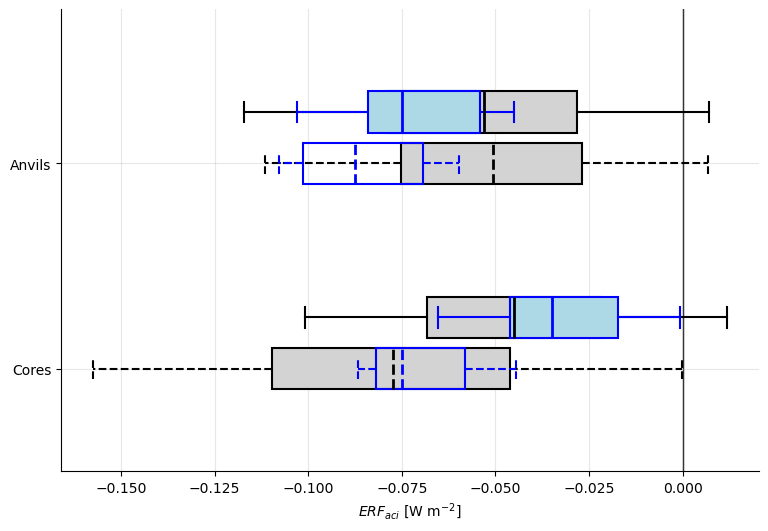

In [3]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
#
input_dir = Path("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/")

# ============================================================
# ERF through cloud controlling factors
# ============================================================
def compute_ERF_ccf_or(cre_ccf, model_so4, component):
    coef_cre = cre_ccf.sel(predictor="SO4_MASS_CON",component=component).coef_spatial
    ERF_CCF_or = (coef_cre*model_so4.dlnSO4).sum(dim=('lat_win','lon_win'))
    mask_ccf = coef_cre.notnull().any(("lat_win", "lon_win"))
    ERF_CCF_or = ERF_CCF_or.where(mask_ccf)
    weights = np.cos(np.deg2rad(coef_cre.lat))
    ERF_CCF_or = ERF_CCF_or.weighted(weights).mean(dim=("lat", "lon"))
    return ERF_CCF_or
#
def compute_ERF_ccf_boot(cre_ccf, component):
    ERF_ccf_boot = cre_ccf.ERF_CCF.sel(component=component) 
    weights = np.cos(np.deg2rad(ERF_ccf_boot.lat))
    ERF_ccf_boot = ERF_ccf_boot.weighted(weights).mean(dim=("lat", "lon")).dropna("model")
    return ERF_ccf_boot
# Data
model_so4 = xr.open_dataset(f"{input_dir}/so4_925_all_models_5deg_27x27.nc")
ds_ERF_core_or=xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
ds_ERF_core_boot=xr.open_dataset(f"{input_dir}/ERF_Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
ds_ERF_anvil_or=xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")
ds_ERF_anvil_boot=xr.open_dataset(f"{input_dir}/ERF_Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")
# 
ERF_ccf_core_or = compute_ERF_ccf_or(ds_ERF_core_or, model_so4, "net")
ERF_ccf_core_boot = compute_ERF_ccf_boot(ds_ERF_core_boot, "net")
#
ERF_ccf_anvil_or = compute_ERF_ccf_or(ds_ERF_anvil_or, model_so4, "net")
ERF_ccf_anvil_boot = compute_ERF_ccf_boot(ds_ERF_anvil_boot, "net")
# ============================================================
# ERF through cloud properties through cloud controlling factors
# ============================================================
def compute_ERF_p_or(cre_p, p_ccf, model_so4, component):
    coef_cre_p = cre_p.sel(component=component).coef_spatial.isel(lat_win=0, lon_win=0)
    coef_p_ccf = p_ccf.sel(predictor="SO4_MASS_CON").coef_spatial.drop_vars('predictor').rename({'component': 'predictor'})
    mask_p = coef_p_ccf.notnull().all(("lat_win", "lon_win"))
    ERF_P_or = (coef_cre_p * (coef_p_ccf * model_so4.dlnSO4).sum(dim=("lat_win", "lon_win"))).sum('predictor')
    ERF_P_or = ERF_P_or.where(mask_p)
    weights = np.cos(np.deg2rad(cre_p.lat))
    ERF_P_or = ERF_P_or.weighted(weights).mean(dim=("lat", "lon"))
    return ERF_P_or
#
def compute_ERF_p_boot(cre_p, p_ccf, component):
    coef_cre_p = cre_p.sel(component=component).coef_spatial.isel(lat_win=0, lon_win=0)
    adj_p_ccf = p_ccf.adj_boot.rename({'component': 'predictor'})
    weights = np.cos(np.deg2rad(cre_p.lat))
    ERF_P_boot = (coef_cre_p * adj_p_ccf).weighted(weights).mean(dim=("lat", "lon"))
    ERF_P_boot =ERF_P_boot.sum('predictor')
    return ERF_P_boot
# Data
ds_cre_p_core_or = xr.open_dataset(f"{input_dir}/Ridge_1x1_results_5deg_cores_ALL_components_conv_CRE_CloudPro.nc")
ds_p_ccf_or= xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
ds_cre_p_core_boot = xr.open_dataset(f"{input_dir}/Ridge_1x1_bootstrap_16_5deg_cores_ALL_components_conv_CRE_CloudPro.nc", engine='netcdf4')
ds_p_ccf_core_boot= xr.open_dataset(f"{input_dir}/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
#
ds_cre_p_anvil_or = xr.open_dataset(f"{input_dir}/Ridge_1x1_results_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc")
ds_p_ccf_anvil_or= xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
ds_cre_p_anvil_boot = xr.open_dataset(f"{input_dir}/Ridge_1x1_bootstrap_3_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc", engine='netcdf4')
ds_p_ccf_anvil_boot= xr.open_dataset(f"{input_dir}/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
#
ERF_P_core_or = compute_ERF_p_or(ds_cre_p_core_or, ds_p_ccf_or, model_so4, "net")
ERF_P_anvil_or = compute_ERF_p_or(ds_cre_p_anvil_or, ds_p_ccf_anvil_or, model_so4, "net")
#
ERF_P_core_boot = compute_ERF_p_boot(ds_cre_p_core_boot, ds_p_ccf_core_boot, "net")
ERF_P_anvil_boot = compute_ERF_p_boot(ds_cre_p_anvil_boot, ds_p_ccf_anvil_boot, "net")

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(9, 6))
y_core, y_anvil = 1.125, 2.125

ax.boxplot([ERF_ccf_core_boot.values.ravel(), ERF_ccf_anvil_boot.values.ravel()], whis=(5, 95), 
           positions=[y_core, y_anvil], widths=0.2, vert=False, showfliers=False, patch_artist=True, 
           boxprops=dict(facecolor="lightgray", edgecolor="black", linewidth=1.5),
           medianprops=dict(color="black", linewidth=2),
           whiskerprops=dict(color="black", linewidth=1.5),
           capprops=dict(color="black", linewidth=1.5))

ax.boxplot([ERF_ccf_core_or.values.ravel(), ERF_ccf_anvil_or.values.ravel()], whis=(5, 95),
           positions=[y_core, y_anvil], widths=0.2, vert=False, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="lightblue", edgecolor="blue", linewidth=1.5),
           medianprops=dict(color="blue", linewidth=2),
           whiskerprops=dict(color="blue", linewidth=1.5),
           capprops=dict(color="blue", linewidth=1.5))

y_core, y_anvil = 0.875, 1.875

ax.boxplot([ERF_P_core_boot.values.ravel(), ERF_P_anvil_boot.values.ravel()], whis=(5, 95),
           positions=[y_core, y_anvil], widths=0.2, vert=False, showfliers=False, patch_artist=True, 
           boxprops=dict(facecolor="lightgray", edgecolor="black", linewidth=1.5, linestyle="--"),
           medianprops=dict(color="black", linewidth=2, linestyle="--"),
           whiskerprops=dict(color="black", linewidth=1.5, linestyle="--"),
           capprops=dict(color="black", linewidth=1.5, linestyle="--"))

ax.boxplot([ERF_P_core_or.values.ravel(), ERF_P_anvil_or.values.ravel()], whis=(5, 95),
           positions=[y_core, y_anvil], widths=0.2, vert=False, showfliers=False, patch_artist=True, 
           boxprops=dict(facecolor="none", edgecolor="blue", linewidth=1.5, linestyle="--"),
           medianprops=dict(color="blue", linewidth=2, linestyle="--"),
           whiskerprops=dict(color="blue", linewidth=1.5, linestyle="--"),
           capprops=dict(color="blue", linewidth=1.5, linestyle="--"))


ax.set_yticks([y_core, y_anvil])
ax.set_yticklabels(["Cores", "Anvils"])
ax.set_xlabel(r"$ERF_{aci}$ [W m$^{-2}$]")
ax.axvline(0, color="black", linewidth=1, zorder=0)
ax.grid(alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

#plt.savefig("/nobackup/proj/disk/bolinc/personal/alur/AC3S/plots/ERF_ccf_mean.png",dpi=300, bbox_inches="tight")

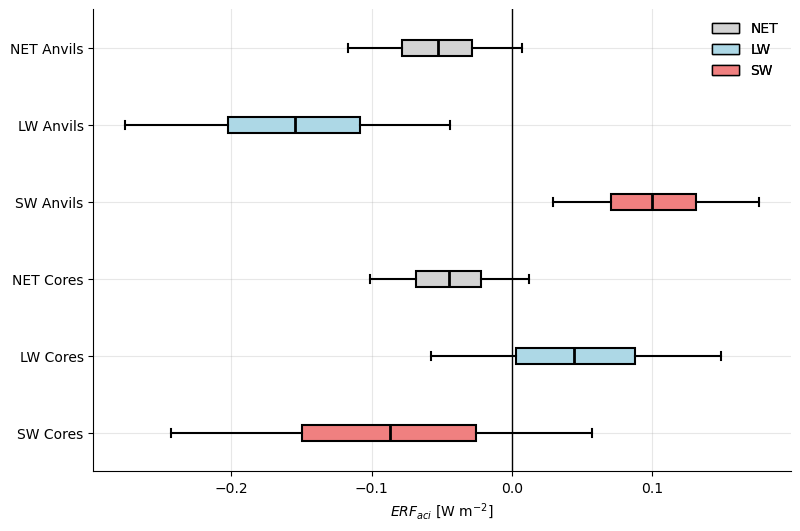

In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ============================================================
# Data
# ============================================================
base = Path("/nobackup/proj/disk/bolinc/personal/alur/AC3S/CMIP6/historical")
model_so4 = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/so4_925_all_models_5deg_27x27.nc")

train_ccf = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_training_data_CloudPro.nc")
train_P_core = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_1x1_training_data_cores_CloudPro.nc")
train_P_anvil = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_1x1_training_data_anvils_CloudPro.nc")

ridge_P_core = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
ridge_P_anvil = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
ridge_CRE_P_core = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_1x1_results_5deg_cores_ALL_components_conv_CRE_CloudPro.nc")
ridge_CRE_P_anvil = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_1x1_results_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc")
ridge_CRE_CCF_core = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/ERF_Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
ridge_CRE_CCF_anvil = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/ERF_Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")


# ============================================================
# Functions
# ============================================================
def get_dP_dSO4(ridge, train):
    return (ridge.sel(predictor="SO4_MASS_CON").coef_spatial / train.sel(predictor="SO4_MASS_CON").ccf_std).drop_vars("predictor").rename({"component": "predictor"})

def get_dCRE_dP(ridge, train):
    return (ridge.coef_spatial / train.CloudPro_std).isel(lat_win=0, lon_win=0)

def global_mean(da):
    weights = np.cos(np.deg2rad(da.lat))
    return da.weighted(weights).mean(("lat", "lon")).dropna("model")


# ============================================================
# ERF through cloud properties
# ============================================================
def calculate_ERF_P(ridge_CRE, train_CRE, ridge_P, train_P):
    dCRE_dP = get_dCRE_dP(ridge_CRE, train_CRE)
    dP_dSO4 = get_dP_dSO4(ridge_P, train_P)
    response = dCRE_dP * (dP_dSO4 * model_so4.dlnSO4).sum(("lat_win", "lon_win"))
    response = response.where(dP_dSO4.notnull().any(("lat_win", "lon_win")))
    return global_mean(response).sum("predictor")

ERF_P_core = calculate_ERF_P(ridge_CRE_P_core, train_P_core, ridge_P_core, train_ccf)
ERF_P_anvil = calculate_ERF_P(ridge_CRE_P_anvil, train_P_anvil, ridge_P_anvil, train_ccf)


# ============================================================
# ERF through cloud controlling factors
# ============================================================
def calculate_ERF_CCF(ridge_CRE):
    response = ridge_CRE["ERF_CCF"]
    #response = (dCRE_dSO4 * model_so4.dlnSO4).sum(("lat_win", "lon_win"))
    #response = response.where(dCRE_dSO4.notnull().any(("lat_win", "lon_win")))
    return global_mean(response)

ERF_CCF_core = calculate_ERF_CCF(ridge_CRE_CCF_core)
ERF_CCF_anvil = calculate_ERF_CCF(ridge_CRE_CCF_anvil)


# ============================================================
# Components
# ============================================================
components = ["sw", "lw", "net"]
types = {"Cores": ERF_CCF_core, "Anvils": ERF_CCF_anvil}

order = [(comp, typ) for typ in ["Cores", "Anvils"] for comp in components]


# ============================================================
# Model colors
# ============================================================
models = ERF_CCF_core.model.values
cmap = plt.cm.tab20
model_colors = {model: cmap(i / len(models)) for i, model in enumerate(models)}


# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(9, 6))

positions = np.arange(1, len(order) + 1)

ccf_data = [
    types[typ].sel(component=comp).values[np.isfinite(types[typ].sel(component=comp).values)]
    for comp, typ in order
]

bp = ax.boxplot(
    ccf_data,
    whis=(5, 95),
    positions=positions,
    widths=0.2,
    vert=False,
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightgray", edgecolor="black", linewidth=1.5),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="black", linewidth=1.5),
    capprops=dict(color="black", linewidth=1.5),
)


# ============================================================
# Box colors
# ============================================================
component_colors = {"sw": "lightcoral", "lw": "lightblue", "net": "lightgray"}

for box, (comp, typ) in zip(bp["boxes"], order):
    box.set_facecolor(component_colors[comp])


# ============================================================
# Axes
# ============================================================
ax.set_yticks(positions)
ax.set_yticklabels([f"{comp.upper()} {typ}" for comp, typ in order])
ax.set_xlabel(r"$ERF_{aci}$ [W m$^{-2}$]")
ax.axvline(0, color="black", linewidth=1)
ax.grid(alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# Component legend
# ============================================================
legend_components = [
    Patch(facecolor="lightgray", edgecolor="black", label="NET"),
    Patch(facecolor="lightblue", edgecolor="black", label="LW"),
    Patch(facecolor="lightcoral", edgecolor="black", label="SW"),
]

leg1 = ax.legend(handles=legend_components, loc="best", frameon=False)
ax.add_artist(leg1)

#plt.savefig("/nobackup/proj/disk/bolinc/personal/alur/AC3S/plots/ERF_ccf_mean_comp.png",dpi=300, bbox_inches="tight")

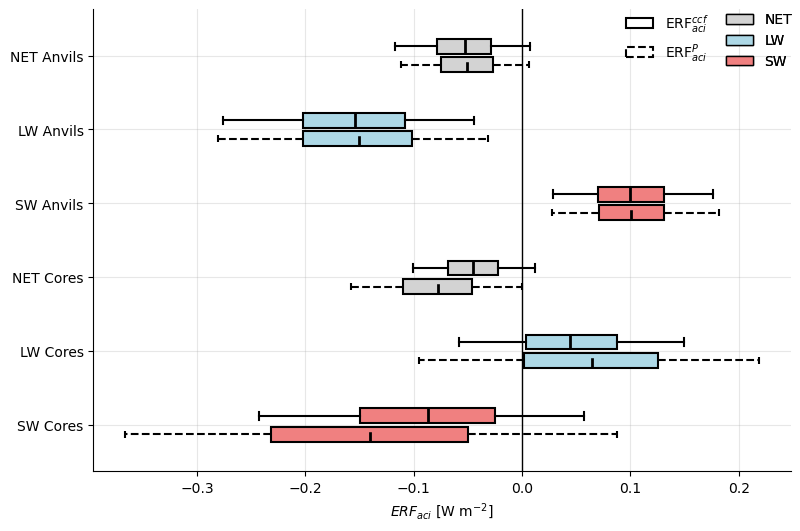

In [6]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

input_dir = Path("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/")

# ============================================================
# ERF through cloud controlling factors
# ============================================================
def compute_ERF_ccf_or(cre_ccf, model_so4, component):
    coef_cre = cre_ccf.sel(predictor="SO4_MASS_CON",component=component).coef_spatial
    ERF_CCF_or = (coef_cre*model_so4.dlnSO4).sum(dim=('lat_win','lon_win'))
    mask_ccf = coef_cre.notnull().any(("lat_win", "lon_win"))
    ERF_CCF_or = ERF_CCF_or.where(mask_ccf)
    weights = np.cos(np.deg2rad(coef_cre.lat))
    ERF_CCF_or = ERF_CCF_or.weighted(weights).mean(dim=("lat", "lon"))
    return ERF_CCF_or
#
def compute_ERF_ccf_boot(cre_ccf, component):
    ERF_ccf_boot = cre_ccf.ERF_CCF.sel(component=component) 
    weights = np.cos(np.deg2rad(ERF_ccf_boot.lat))
    ERF_ccf_boot = ERF_ccf_boot.weighted(weights).mean(dim=("lat", "lon")).dropna("model")
    return ERF_ccf_boot
# Data
model_so4 = xr.open_dataset(f"{input_dir}/so4_925_all_models_5deg_27x27.nc")
ds_ERF_core_or=xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
ds_ERF_core_boot=xr.open_dataset(f"{input_dir}/ERF_Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro.nc")
ds_ERF_anvil_or=xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")
ds_ERF_anvil_boot=xr.open_dataset(f"{input_dir}/ERF_Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro.nc")
# ============================================================
# Components
# ============================================================
components = ["sw", "lw", "net"]
#
ERF_ccf_core_boot = {comp: compute_ERF_ccf_boot(ds_ERF_core_boot, comp) for comp in components}
ERF_ccf_anvil_boot = {comp: compute_ERF_ccf_boot(ds_ERF_anvil_boot, comp) for comp in components}
# ============================================================
# ERF through cloud properties through cloud controlling factors
# ============================================================
def compute_ERF_p_or(cre_p, p_ccf, model_so4, component):
    coef_cre_p = cre_p.sel(component=component).coef_spatial.isel(lat_win=0, lon_win=0)
    coef_p_ccf = p_ccf.sel(predictor="SO4_MASS_CON").coef_spatial.drop_vars('predictor').rename({'component': 'predictor'})
    mask_p = coef_p_ccf.notnull().all(("lat_win", "lon_win"))
    ERF_P_or = (coef_cre_p * (coef_p_ccf * model_so4.dlnSO4).sum(dim=("lat_win", "lon_win"))).sum('predictor')
    ERF_P_or = ERF_P_or.where(mask_p)
    weights = np.cos(np.deg2rad(cre_p.lat))
    ERF_P_or = ERF_P_or.weighted(weights).mean(dim=("lat", "lon"))
    return ERF_P_or
#
def compute_ERF_p_boot(cre_p, p_ccf, component):
    coef_cre_p = cre_p.sel(component=component).coef_spatial.isel(lat_win=0, lon_win=0)
    adj_p_ccf = p_ccf.adj_boot.rename({'component': 'predictor'})
    weights = np.cos(np.deg2rad(cre_p.lat))
    ERF_P_boot = (coef_cre_p * adj_p_ccf).weighted(weights).mean(dim=("lat", "lon"))
    ERF_P_boot =ERF_P_boot.sum('predictor')
    return ERF_P_boot
# Data
ds_cre_p_core_or = xr.open_dataset(f"{input_dir}/Ridge_1x1_results_5deg_cores_ALL_components_conv_CRE_CloudPro.nc")
ds_p_ccf_or= xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
ds_cre_p_core_boot = xr.open_dataset(f"{input_dir}/Ridge_1x1_bootstrap_16_5deg_cores_ALL_components_conv_CRE_CloudPro.nc", engine='netcdf4')
ds_p_ccf_core_boot= xr.open_dataset(f"{input_dir}/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
#
ds_cre_p_anvil_or = xr.open_dataset(f"{input_dir}/Ridge_1x1_results_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc")
ds_p_ccf_anvil_or= xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
ds_cre_p_anvil_boot = xr.open_dataset(f"{input_dir}/Ridge_1x1_bootstrap_3_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc", engine='netcdf4')
ds_p_ccf_anvil_boot= xr.open_dataset(f"{input_dir}/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
#
ERF_p_core_boot = {comp: compute_ERF_p_boot(ds_cre_p_core_boot, ds_p_ccf_core_boot, comp) for comp in components}
ERF_p_anvil_boot = {comp: compute_ERF_p_boot(ds_cre_p_anvil_boot, ds_p_ccf_anvil_boot, comp) for comp in components}
# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(9, 6))
#
types = {"Cores": ERF_ccf_core_boot, "Anvils": ERF_ccf_anvil_boot}
order = [(comp, typ) for typ in ["Cores", "Anvils"] for comp in components]
positions_labels = np.arange(1, len(order) + 1)
positions_ccf = positions_labels + 0.125
ccf_data = [types[typ][comp].values.ravel() for comp, typ in order]
ccf_data = [data[np.isfinite(data)] for data in ccf_data]
#
bp = ax.boxplot(
    ccf_data,
    whis=(5, 95),
    positions=positions_ccf,
    widths=0.2,
    vert=False,
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightgray", edgecolor="black", linewidth=1.5),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="black", linewidth=1.5),
    capprops=dict(color="black", linewidth=1.5)
)
component_colors = {
    "sw": "lightcoral",
    "lw": "lightblue",
    "net": "lightgray"
}

for box, (comp, typ) in zip(bp["boxes"], order):
    box.set_facecolor(component_colors[comp])

types = {"Cores": ERF_p_core_boot, "Anvils": ERF_p_anvil_boot}
order = [(comp, typ) for typ in ["Cores", "Anvils"] for comp in components]
positions_labels = np.arange(1, len(order) + 1)
positions_P   = positions_labels - 0.125
p_data = [types[typ][comp].values.ravel() for comp, typ in order]
p_data = [data[np.isfinite(data)] for data in p_data]
#
bp = ax.boxplot(
    p_data,
    whis=(5, 95),
    positions=positions_P,
    widths=0.2,
    vert=False,
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightgray", edgecolor="black", linewidth=1.5, linestyle="--"),
    medianprops=dict(color="black", linewidth=2, linestyle="--"),
    whiskerprops=dict(color="black", linewidth=1.5, linestyle="--"),
    capprops=dict(color="black", linewidth=1.5, linestyle="--")
)
component_colors = {
    "sw": "lightcoral",
    "lw": "lightblue",
    "net": "lightgray"
}

for box, (comp, typ) in zip(bp["boxes"], order):
    box.set_facecolor(component_colors[comp])

# ============================================================
# Axes
# ============================================================
ax.set_yticks(positions_labels)
ax.set_yticklabels([f"{comp.upper()} {typ}" for comp, typ in order])
ax.set_xlabel(r"$ERF_{aci}$ [W m$^{-2}$]")
ax.axvline(0, color="black", linewidth=1)
ax.grid(alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ============================================================
# Component legend
# ============================================================
# Legend
legend_ccf = Patch(facecolor="white", edgecolor="black", linewidth=1.5, linestyle="-", label=r"ERF$_{aci}^{ccf}$")
legend_P = Patch(facecolor="white", edgecolor="black", linewidth=1.5, linestyle="--", label=r"ERF$_{aci}^P$")
leg1 = ax.legend(handles=[legend_ccf, legend_P], frameon=False, loc="upper right",bbox_to_anchor=(0.9, 1.02))
ax.add_artist(leg1)

legend_components = [
    Patch(facecolor="lightgray", edgecolor="black", label="NET"),
    Patch(facecolor="lightblue", edgecolor="black", label="LW"),
    Patch(facecolor="lightcoral", edgecolor="black", label="SW")
]

leg2 = ax.legend(handles=legend_components, loc="best", frameon=False, bbox_to_anchor=(1.02, 1.02))

ax.add_artist(leg2)


# plt.savefig(
#     "/nobackup/proj/disk/bolinc/personal/alur/AC3S/plots/ERF_ccf_mean_comp.png",
#     dpi=300,
#     bbox_inches="tight"
# )


/tmp/ipykernel_3100681/1419353655.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(
/tmp/ipykernel_3100681/1419353655.py:64: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(


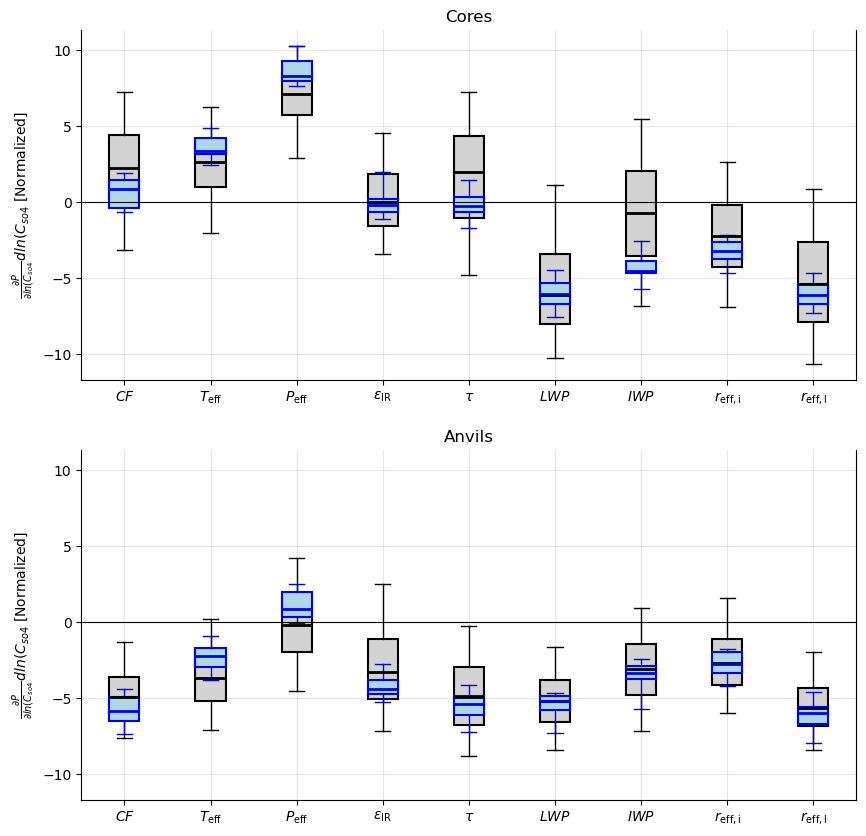

In [7]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from pathlib import Path
import pandas as pd
from matplotlib.lines import Line2D
#
#data from Ridge regression results
ridge_P_ccf_core = xr.open_dataset(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
ridge_p_ccf_core_boots = xr.open_dataset(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
ridge_P_ccf_anvil = xr.open_dataset(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
ridge_p_ccf_anvil_boots = xr.open_dataset(f"/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
model_so4 = xr.open_dataset("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/so4_925_all_models_5deg_27x27.nc")
# Cores
d_P_dlnCso4_core = (ridge_P_ccf_core.sel(predictor='SO4_MASS_CON').coef_spatial) # 9 components (P)
d_P_dlnCso4_core = d_P_dlnCso4_core.drop_vars('predictor').rename({'component': 'predictor'})
mask_core_P = d_P_dlnCso4_core.isnull().all(("lat_win", "lon_win"))
P_core = (d_P_dlnCso4_core * model_so4.dlnSO4).sum(dim=('lat_win','lon_win')).where(~mask_core_P)
weights_lat = np.cos(np.deg2rad(d_P_dlnCso4_core.lat))
dP_core_or = P_core.weighted(weights_lat).mean(dim=('lat','lon')) / P_core.weighted(weights_lat).mean(dim=('lat','lon')).std('model')
#
P_core = ridge_p_ccf_core_boots.adj_boot
weights_lat = np.cos(np.deg2rad(ridge_p_ccf_core_boots.lat))
dP_core = P_core.weighted(weights_lat).mean(dim=('lat','lon')) / P_core.weighted(weights_lat).mean(dim=('lat','lon')).std('model')
#
# Anvils
d_P_dlnCso4_anvil = (ridge_P_ccf_anvil.sel(predictor='SO4_MASS_CON').coef_spatial) # 9 components (P)
d_P_dlnCso4_anvil = d_P_dlnCso4_anvil.drop_vars('predictor').rename({'component': 'predictor'})
mask_anvil_P = d_P_dlnCso4_anvil.isnull().all(("lat_win", "lon_win"))
P_anvil = (d_P_dlnCso4_anvil * model_so4.dlnSO4).sum(dim=('lat_win','lon_win')).where(~mask_anvil_P)
weights_lat = np.cos(np.deg2rad(d_P_dlnCso4_anvil.lat))
dP_anvil_or = P_anvil.weighted(weights_lat).mean(dim=('lat','lon')) / P_anvil.weighted(weights_lat).mean(dim=('lat','lon')).std('model')
#
P_anvil = ridge_p_ccf_anvil_boots.adj_boot
weights_lat = np.cos(np.deg2rad(ridge_p_ccf_anvil_boots.lat))
dP_anvil = P_anvil.weighted(weights_lat).mean(dim=('lat','lon')) / P_anvil.weighted(weights_lat).mean(dim=('lat','lon')).std('model')
#
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(10, 10), sharey=True)
# Cores

axs[0].boxplot(
    [dP_core.isel(component=i).values.flatten() for i in range(dP_core.sizes["component"])], whis=(5, 95), 
    labels=dP_core.component.values, widths=0.35,
        boxprops=dict(facecolor="lightgray", edgecolor="black", linewidth=1.5),
        vert=True,
        showfliers=False,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black")
)
axs[0].boxplot(dP_core_or.values.T,tick_labels=dP_core_or.predictor.values, widths=0.35, whis=(5, 95), 
        boxprops=dict(facecolor="lightblue", edgecolor="blue", linewidth=1.5),
        vert=True,
        showfliers=False,
        patch_artist=True,
        medianprops=dict(color="blue", linewidth=2),
        whiskerprops=dict(color="blue"),
        capprops=dict(color="blue")
    )

axs[1].boxplot(
    [dP_anvil.isel(component=i).values.flatten() for i in range(dP_anvil.sizes["component"])], whis=(5, 95),
    labels=dP_anvil.component.values, widths=0.35,
        boxprops=dict(facecolor="lightgray", edgecolor="black", linewidth=1.5),
        vert=True,
        showfliers=False,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black")
)
axs[1].boxplot(dP_anvil_or.values.T,tick_labels=dP_anvil_or.predictor.values, widths=0.35, whis=(5, 95),
        boxprops=dict(facecolor="lightblue", edgecolor="blue", linewidth=1.5),
        vert=True,
        showfliers=False,
        patch_artist=True,
        medianprops=dict(color="blue", linewidth=2),
        whiskerprops=dict(color="blue"),
        capprops=dict(color="blue")
    )
axs[0].set_title('Cores')
axs[1].set_title('Anvils')
xlabels = [r"$CF$", r"$T_{\mathrm{eff}}$", r"$P_{\mathrm{eff}}$", r"$\epsilon_{\mathrm{IR}}$", r"$\tau$", r"$LWP$",
          r"$IWP$", r"$r_{\mathrm{eff,i}}$", r"$r_{\mathrm{eff,l}}$"]
n = dP_core.sizes["component"]
positions = np.arange(1, n + 1)
for ax in axs.ravel():
    ax.grid(alpha=0.3)
    ax.spines["top"].set_visible(False)
    # ax.spines["right"].set_visible(False)
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_ylabel(r"$\frac{\partial P}{\partial ln(C_{so4}}dln(C_{so4}$ [Normalized]")
    ax.set_xticks(positions)
    ax.set_xticklabels(xlabels)
#plt.savefig("/nobackup/proj/disk/bolinc/personal/alur/AC3S/plots/dP_dln(Cso4).png", dpi=300, bbox_inches="tight")

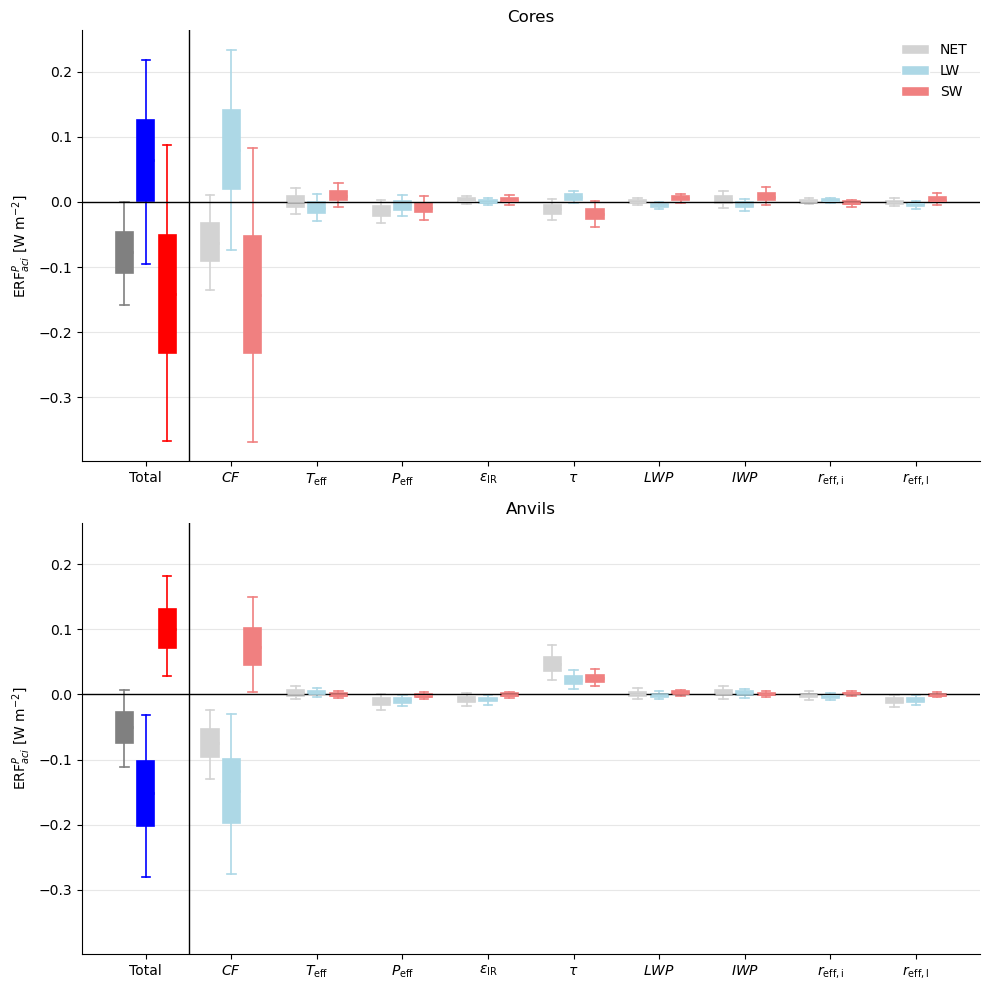

In [9]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from pathlib import Path
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
#
input_dir = Path("/nobackup/proj/disk/bolinc/personal/alur/AC3S/prod_data/")
#
# ============================================================
# ERF through cloud properties through cloud controlling factors
# ============================================================
def compute_ERF_p_or(cre_p, p_ccf, model_so4, component):
    coef_cre_p = cre_p.sel(component=component).coef_spatial.isel(lat_win=0, lon_win=0)
    coef_p_ccf = p_ccf.sel(predictor="SO4_MASS_CON").coef_spatial.drop_vars('predictor').rename({'component': 'predictor'})
    mask_p = coef_p_ccf.notnull().all(("lat_win", "lon_win"))
    ERF_P_or = (coef_cre_p * (coef_p_ccf * model_so4.dlnSO4).sum(dim=("lat_win", "lon_win")))
    ERF_P_or = ERF_P_or.where(mask_p)
    weights = np.cos(np.deg2rad(cre_p.lat))
    ERF_P_or = ERF_P_or.weighted(weights).mean(dim=("lat", "lon"))
    return ERF_P_or
#
def compute_ERF_p_boot(cre_p, p_ccf, component):
    coef_cre_p = cre_p.sel(component=component).coef_spatial.isel(lat_win=0, lon_win=0)
    adj_p_ccf = p_ccf.adj_boot.rename({'component': 'predictor'})
    weights = np.cos(np.deg2rad(cre_p.lat))
    ERF_P_boot = (coef_cre_p * adj_p_ccf).weighted(weights).mean(dim=("lat", "lon"))
    ERF_P_boot =ERF_P_boot
    return ERF_P_boot
#
components = ["sw", "lw", "net"]
# Data
ds_cre_p_core_or = xr.open_dataset(f"{input_dir}/Ridge_1x1_results_5deg_cores_ALL_components_conv_CRE_CloudPro.nc")
ds_p_ccf_or= xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
ds_cre_p_core_boot = xr.open_dataset(f"{input_dir}/Ridge_1x1_bootstrap_16_5deg_cores_ALL_components_conv_CRE_CloudPro.nc", engine='netcdf4')
ds_p_ccf_core_boot= xr.open_dataset(f"{input_dir}/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_cores_ALL_components_conv_CloudPro_ccfs.nc")
#
ds_cre_p_anvil_or = xr.open_dataset(f"{input_dir}/Ridge_1x1_results_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc")
ds_p_ccf_anvil_or= xr.open_dataset(f"{input_dir}/Ridge_27x27_results_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
ds_cre_p_anvil_boot = xr.open_dataset(f"{input_dir}/Ridge_1x1_bootstrap_3_5deg_anvils_ALL_components_conv_CRE_CloudPro.nc", engine='netcdf4')
ds_p_ccf_anvil_boot= xr.open_dataset(f"{input_dir}/Ridge_27x27_bootstrap_5_5deg_SO4_MASS_CON_anvils_ALL_components_conv_CloudPro_ccfs.nc")
#
ERF_p_core_boot = {comp: compute_ERF_p_boot(ds_cre_p_core_boot, ds_p_ccf_core_boot, comp) for comp in components}
ERF_p_anvil_boot = {comp: compute_ERF_p_boot(ds_cre_p_anvil_boot, ds_p_ccf_anvil_boot, comp) for comp in components}
#
#
components = ["net", "lw", "sw"]

total_colors = {
    "net": "grey",
    "lw": "blue",
    "sw": "red"
}

predictor_colors = {
    "net": "lightgray",
    "lw": "lightblue",
    "sw": "lightcoral"
}

labels = {
    "net": "NET",
    "lw": "LW",
    "sw": "SW"
}

predictor_labels = [r"$CF$", r"$T_{\mathrm{eff}}$", r"$P_{\mathrm{eff}}$", r"$\epsilon_{\mathrm{IR}}$", r"$\tau$", r"$LWP$",
                    r"$IWP$", r"$r_{\mathrm{eff,i}}$", r"$r_{\mathrm{eff,l}}$"]

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(10, 10), sharey=True)
# Posiciones de los tres boxplots para cada predictor
offsets = [-0.25, 0, 0.25]
# ============================================================
# CORES + ANVILS
# ============================================================

for j, (ax, data_da) in enumerate([(axs[0], ERF_p_core_boot), (axs[1], ERF_p_anvil_boot)]):
    predictors = data_da['net'].predictor.values
    # Total + predictors
    categories = ["Total"] + list(predictors)
    # x = 1 -> Total
    # x = 2, 3, ... -> individual predictors
    x = np.arange(1, len(categories) + 1)
    for i, comp in enumerate(components):
        da = data_da[comp]
        # Total
        total = da.sum("predictor")
        total_data = total.values.ravel()#[np.isfinite(total.values)]
        # Individual predictors
        predictor_data = [da.sel(predictor=p).values.ravel() for p in predictors]
        data = [total_data] + predictor_data
        # ----------------------------------------------------
        # Boxplot TOTAL
        # ----------------------------------------------------
        ax.boxplot([total_data], positions=[x[0] + offsets[i]], whis=(5, 95),
                   widths=0.20, showfliers=False, patch_artist=True,
            boxprops=dict(facecolor=total_colors[comp],
                edgecolor=total_colors[comp],
                linewidth=1.2),
            medianprops=dict(color=total_colors[comp],
                linewidth=2),
            whiskerprops=dict(color=total_colors[comp],
                linewidth=1.2),
            capprops=dict(color=total_colors[comp],
                linewidth=1.2)
                  )
        # ----------------------------------------------------
        # Boxplots INDIVIDUAL PREDICTORS
        # ----------------------------------------------------
        ax.boxplot(predictor_data, positions=x[1:] + offsets[i], whis=(5, 95), 
                   widths=0.20, showfliers=False, patch_artist=True,
            boxprops=dict(facecolor=predictor_colors[comp],
                edgecolor=predictor_colors[comp],
                linewidth=1.2),
            medianprops=dict(color=predictor_colors[comp],
                linewidth=2),
            whiskerprops=dict(color=predictor_colors[comp],
                linewidth=1.2),
            capprops=dict(color=predictor_colors[comp],
                linewidth=1.2)
                  )
    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------
    ax.set_xticks(x)
    ax.set_xticklabels(["Total"] + predictor_labels)
    ax.axhline(0, color="black", linewidth=1)
    ax.axvline(1.5, color="black", linewidth=1)
    ax.grid(alpha=0.3, axis="y")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylabel(r"ERF$^P_{aci}$ [W m$^{-2}$]")
    
    #ax.set_xlabel("P")

# ============================================================
# Labels / titles
# ============================================================
axs[0].set_title("Cores")
axs[1].set_title("Anvils")
#axs[0].set_ylabel(r"ERF$^P_{aci}$ [W m$^{-2}$]")
# ============================================================
# Legend
# ============================================================

legend_elements = [Patch(facecolor="lightgray", edgecolor="white", label="NET"),
                   Patch(facecolor="lightblue", edgecolor="white", label="LW"),
                   Patch(facecolor="lightcoral", edgecolor="white", label="SW")]
axs[0].legend(handles=legend_elements, loc="upper right", frameon=False,)
plt.tight_layout()
plt.savefig("/nobackup/proj/disk/bolinc/personal/alur/AC3S/plots/ERF_P_mean_comp.png", dpi=300, bbox_inches="tight")




In [127]:
total

<xarray.DataArray (bootstrap: 1000, model: 19)> Size: 152kB
array([[-0.14187857, -0.12346919, -0.10688879, ..., -0.11587929,
        -0.08739227, -0.09951423],
       [-0.15171322, -0.1359774 , -0.1309855 , ..., -0.11912812,
        -0.11303868, -0.11531596],
       [-0.17247196, -0.14905233, -0.14020934, ..., -0.14552528,
        -0.12703133, -0.12689786],
       ...,
       [-0.07138731, -0.07493054, -0.0719773 , ..., -0.07725193,
        -0.07112921, -0.07031264],
       [-0.12212266, -0.11474161, -0.1008304 , ..., -0.11270598,
        -0.09660316, -0.10243213],
       [-0.16697097, -0.12911861, -0.12397662, ..., -0.11711952,
        -0.0969838 , -0.10086029]], shape=(1000, 19))
Coordinates:
    component  <U3 12B 'net'
  * bootstrap  (bootstrap) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
  * model      (model) <U17 1kB 'BCC-ESM1' 'CESM2' ... 'NorESM2-LM' 'NorESM2-MM'

In [123]:
predictors = ERF_p_core_boot['net'].predictor.values
# Total + predictors
categories = ["Total"] + list(predictors)
# x = 1 -> Total

In [124]:
categories

['Total',
 np.str_('cf_deep'),
 np.str_('fbct_cld_eff_temp'),
 np.str_('fbct_cld_eff_press'),
 np.str_('fbct_cld_ir_emiss'),
 np.str_('fbct_cld_od'),
 np.str_('fbct_cld_lwp'),
 np.str_('fbct_cld_iwp'),
 np.str_('fbct_cld_ice_radius'),
 np.str_('fbct_cld_liq_radius')]